# Clase 13 — Análisis espectral de formas
## Tutorial práctico: ShapeDNA, análisis de Fourier en variedades, calor, mapas de difusión, HKS y WKS

**CC5513 Procesamiento Geométrico y Análisis de Formas** · Ivan Sipiran · DCC, Universidad de Chile

En la primera parte de la clase vimos el operador de Laplace–Beltrami, su discretización con
cotangentes y el problema de valores propios generalizado

$$\mathbf{L}\,\boldsymbol\Phi = \mathbf{M}\,\boldsymbol\Phi\,\boldsymbol\Lambda, \qquad \boldsymbol\Phi^\top\mathbf{M}\boldsymbol\Phi=\mathbf{I}.$$

Este tutorial parte **desde ahí** y recorre el resto de las slides (35–57), siempre con código
ejecutable:

| Bloque | Tema (slides) | Ejercicios | Tiempo |
|---|---|---|---|
| 0 | Preparación: datos sintéticos casi isométricos | — | 10 min |
| 1 | Espectro y **ShapeDNA** (35) | 1–3 | 40 min |
| 2 | **Eigenfunciones** y **Fourier en variedades** (36–40) | 4–5 | 30 min |
| 3 | **Ecuación del calor** y **kernel de calor** (41–47) | 6–7 | 30 min |
| 4 | **Mapas y distancias de difusión** (48–51) | 8 | 25 min |
| 5 | Descriptores locales: **HKS** y **WKS**, correspondencias (52–57) | 9–12 | 40 min |
| 6 | Cierre y preguntas | — | 5 min |

**Cómo trabajar.** Cada ejercicio tiene una celda con `TODO` y una celda de tests con `assert`.
Si los tests pasan, sigue. Las soluciones están plegadas al final del notebook.
Todo se ejecuta en Colab sin GPU ni descargas (sólo NumPy, SciPy, Matplotlib y scikit-image,
que Colab ya trae). La ejecución completa toma alrededor de 2 minutos.

**Convención de signo.** Igual que en las slides, usamos el Laplaciano **positivo**:
$\Delta = \mathbf{M}^{-1}\mathbf{L}$ con $\mathbf L = \mathbf D - \mathbf W$ semidefinida positiva,
así que $0=\lambda_1\le\lambda_2\le\dots$ y la ecuación del calor es $f_t = -\Delta f$.

---
# Bloque 0 — Preparación (10 min)

La celda siguiente define todo lo que **no** es materia de hoy: generación de mallas, el
Laplaciano de cotangentes y la matriz de masa (ya los implementamos en la Clase 4),
geodésicas aproximadas con Dijkstra y un pequeño renderizador.

In [1]:
#@title Utilidades de la clase (ejecutar sin modificar — doble clic para ver el código)
import time, warnings
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as sla
import scipy.linalg as sl
from scipy.sparse.csgraph import dijkstra
from scipy.spatial import cKDTree
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib import colors as mcolors
from skimage.measure import marching_cubes

np.set_printoptions(precision=4, suppress=True, linewidth=120)
plt.rcParams.update({'figure.dpi': 90, 'axes.grid': False})

# ------------------------------------------------------------------
# 1. Mallas básicas
# ------------------------------------------------------------------
def edges_of(F):
    """Aristas únicas (i<j) de una malla triangular."""
    E = np.sort(np.vstack([F[:, [0, 1]], F[:, [1, 2]], F[:, [2, 0]]]), 1)
    return np.unique(E, axis=0)

def euler_characteristic(V, F):
    return len(V) - len(edges_of(F)) + len(F)

def face_areas(V, F):
    return 0.5 * np.linalg.norm(np.cross(V[F[:, 1]] - V[F[:, 0]], V[F[:, 2]] - V[F[:, 0]]), axis=1)

def icosphere(level=4):
    """Esfera unitaria por subdivisión de un icosaedro (10·4^level + 2 vértices)."""
    t = (1 + 5 ** .5) / 2
    V = np.array([[-1, t, 0], [1, t, 0], [-1, -t, 0], [1, -t, 0], [0, -1, t], [0, 1, t],
                  [0, -1, -t], [0, 1, -t], [t, 0, -1], [t, 0, 1], [-t, 0, -1], [-t, 0, 1]], float)
    F = np.array([[0, 11, 5], [0, 5, 1], [0, 1, 7], [0, 7, 10], [0, 10, 11], [1, 5, 9], [5, 11, 4],
                  [11, 10, 2], [10, 7, 6], [7, 1, 8], [3, 9, 4], [3, 4, 2], [3, 2, 6], [3, 6, 8],
                  [3, 8, 9], [4, 9, 5], [2, 4, 11], [6, 2, 10], [8, 6, 7], [9, 8, 1]])
    V /= np.linalg.norm(V, axis=1, keepdims=True)
    for _ in range(level):
        cache, Vl, nf = {}, list(V), []
        def mid(i, j):
            k = (min(i, j), max(i, j))
            if k not in cache:
                m = (Vl[i] + Vl[j]) / 2
                Vl.append(m / np.linalg.norm(m)); cache[k] = len(Vl) - 1
            return cache[k]
        for a, b, c in F:
            ab, bc, ca = mid(a, b), mid(b, c), mid(c, a)
            nf += [[a, ab, ca], [b, bc, ab], [c, ca, bc], [ab, bc, ca]]
        V, F = np.array(Vl), np.array(nf)
    return V, F

def torus(R=1.0, r=0.4, nu=60, nv=24):
    u, v = np.meshgrid(np.arange(nu) * 2 * np.pi / nu, np.arange(nv) * 2 * np.pi / nv, indexing='ij')
    V = np.stack([(R + r * np.cos(v)) * np.cos(u), (R + r * np.cos(v)) * np.sin(u), r * np.sin(v)], -1).reshape(-1, 3)
    idx = lambda i, j: (i % nu) * nv + (j % nv)
    F = []
    for i in range(nu):
        for j in range(nv):
            F += [[idx(i, j), idx(i + 1, j), idx(i + 1, j + 1)], [idx(i, j), idx(i + 1, j + 1), idx(i, j + 1)]]
    return V, np.array(F)

# ------------------------------------------------------------------
# 2. Laplaciano de cotangentes y matriz de masa (repaso de la Clase 4)
#    Convención: L = D - W es SEMIDEFINIDA POSITIVA, de modo que
#    Δ = M^{-1} L tiene valores propios 0 = λ1 <= λ2 <= ...  (signo de las slides)
# ------------------------------------------------------------------
def cotan_laplacian(V, F):
    n = len(V); I, J, W = [], [], []
    for i in range(3):
        a, b, c = F[:, i], F[:, (i + 1) % 3], F[:, (i + 2) % 3]
        u, v = V[b] - V[a], V[c] - V[a]
        cot = (u * v).sum(1) / np.linalg.norm(np.cross(u, v), axis=1)   # cotangente del ángulo en a
        I += [b, c]; J += [c, b]; W += [0.5 * cot, 0.5 * cot]
    W = sp.coo_matrix((np.concatenate(W), (np.concatenate(I), np.concatenate(J))), shape=(n, n)).tocsr()
    return (sp.diags(np.asarray(W.sum(1)).ravel()) - W).tocsr()

def mass_matrix(V, F):
    """Masa baricéntrica concentrada (diagonal): un tercio del área de cada triángulo incidente."""
    A = face_areas(V, F)
    return sp.diags(np.bincount(F.ravel(), np.repeat(A / 3, 3), minlength=len(V)))

def implicit_heat(L, M, f0, t, nsteps=200):
    """Referencia por pasos de tiempo: Euler implícito (M + dt L) f_{n+1} = M f_n."""
    dt = t / nsteps
    lu = sla.splu((M + dt * L).tocsc())
    f = np.array(f0, float)
    for _ in range(nsteps):
        f = lu.solve(M @ f)
    return f

# ------------------------------------------------------------------
# 3. Geodésicas aproximadas (Dijkstra sobre el grafo de aristas)
# ------------------------------------------------------------------
def edge_graph(V, F):
    E = edges_of(F); w = np.linalg.norm(V[E[:, 0]] - V[E[:, 1]], axis=1)
    return sp.coo_matrix((w, (E[:, 0], E[:, 1])), shape=(len(V), len(V))).tocsr()

def geodesics_from(V, F, sources):
    """Matriz (len(sources) x n) de distancias geodésicas aproximadas."""
    return dijkstra(edge_graph(V, F), directed=False, indices=np.atleast_1d(sources))

# ------------------------------------------------------------------
# 4. Criaturas sintéticas: SDF de conos redondeados + marching cubes
# ------------------------------------------------------------------
def _sd_cone(P, a, b, ra, rb):
    ab = b - a
    t = np.clip(((P - a) @ ab) / (ab @ ab), 0, 1)
    return np.linalg.norm(P - (a + t[:, None] * ab), axis=1) - (ra + (rb - ra) * t)

def _smin(a, b, k):
    h = np.clip(0.5 + 0.5 * (b - a) / k, 0, 1)
    return b * (1 - h) + a * h - k * h * (1 - h)

def _bone(name, a, b, ra, rb, parent):
    return dict(name=name, a=np.array(a, float), b=np.array(b, float), ra=ra, rb=rb, r=0.5 * (ra + rb), parent=parent)

def humanoid_bones():
    bs = [_bone('spine', (0, -.15, 0), (0, .7, 0), .25, .23, None),
          _bone('head', (0, .78, 0), (0, 1.12, 0), .08, .19, 'spine')]
    for s, n in [(1, 'L'), (-1, 'R')]:
        bs += [_bone('arm' + n, (s * .25, .62, 0), (s * .75, .62, 0), .105, .09, 'spine'),
               _bone('fore' + n, (s * .75, .62, 0), (s * 1.22, .62, 0), .09, .075, 'arm' + n),
               _bone('thigh' + n, (s * .13, -.2, 0), (s * .17, -.72, 0), .13, .105, 'spine'),
               _bone('shin' + n, (s * .17, -.72, 0), (s * .19, -1.25, 0), .105, .085, 'thigh' + n)]
    return bs

def quadruped_bones():
    bs = [_bone('body', (-.6, 0, 0), (.6, 0, 0), .29, .27, None),
          _bone('neck', (.55, .1, 0), (.85, .5, 0), .14, .12, 'body'),
          _bone('head', (.85, .5, 0), (1.15, .42, 0), .16, .10, 'neck'),
          _bone('tail', (-.65, .05, 0), (-1.25, .3, 0), .08, .045, 'body')]
    for x, fx in [(.45, 'F'), (-.45, 'H')]:
        for z, fz in [(.21, 'L'), (-.21, 'R')]:
            n = fx + fz
            bs += [_bone('up' + n, (x, -.1, z), (x, -.55, z), .11, .09, 'body'),
                   _bone('lo' + n, (x, -.55, z), (x + .03, -1.0, z), .09, .07, 'up' + n)]
    return bs

def starfish_bones():
    bs = [_bone('core', (0, -.06, 0), (0, .1, 0), .33, .28, None)]
    for i in range(5):
        th = 2 * np.pi * i / 5 + np.pi / 2; d = np.array([np.cos(th), 0, np.sin(th)])
        bs += [_bone(f'a{i}', .25 * d, .85 * d, .15, .115, 'core'),
               _bone(f'b{i}', .85 * d, 1.45 * d, .115, .06, f'a{i}')]
    return bs

def _num_grad(f, P, h=1e-4):
    g = np.zeros_like(P)
    for i in range(3):
        e = np.zeros(3); e[i] = h
        g[:, i] = (f(P + e) - f(P - e)) / (2 * h)
    return g

def _clean(V, F):
    _, inv = np.unique(np.round(V / 1e-7).astype(np.int64), axis=0, return_inverse=True)
    inv = inv.ravel(); Vm = np.zeros((inv.max() + 1, 3)); Vm[inv] = V; F = inv[F]
    F = F[(F[:, 0] != F[:, 1]) & (F[:, 1] != F[:, 2]) & (F[:, 0] != F[:, 2])]
    used = np.unique(F); remap = -np.ones(len(Vm), int); remap[used] = np.arange(len(used))
    return Vm[used], remap[F]

def mesh_from_bones(bones, h=0.035, relax_iters=8, k=0.12):
    """Malla de la unión suave de los huesos: marching cubes + relajación tangencial
    con reproyección a la superficie (triángulos casi equiláteros)."""
    def f(P):
        d = None
        for b in bones:
            di = _sd_cone(P, b['a'], b['b'], b['ra'], b['rb'])
            d = di if d is None else _smin(d, di, k)
        return d
    P = np.concatenate([np.stack([b['a'], b['b']]) for b in bones])
    lo, hi = P.min(0) - .35, P.max(0) + .35
    xs = [np.arange(lo[i], hi[i] + h, h) for i in range(3)]
    G = np.stack(np.meshgrid(*xs, indexing='ij'), -1).reshape(-1, 3)
    vol = f(G).reshape(len(xs[0]), len(xs[1]), len(xs[2]))
    V, F, _, _ = marching_cubes(vol, 0.0, spacing=(h, h, h))
    V, F = _clean(V + lo, F)
    E = edges_of(F); n = len(V)
    A = sp.coo_matrix((np.ones(2 * len(E)), (np.r_[E[:, 0], E[:, 1]], np.r_[E[:, 1], E[:, 0]])), shape=(n, n)).tocsr()
    deg = np.asarray(A.sum(1)).ravel()
    for _ in range(relax_iters):
        g = _num_grad(f, V); nrm = g / np.linalg.norm(g, axis=1, keepdims=True)
        D = (A @ V) / deg[:, None] - V
        V = V + 0.5 * (D - (D * nrm).sum(1, keepdims=True) * nrm)
        for _ in range(2):
            g = _num_grad(f, V); V = V - (f(V) / (g * g).sum(1))[:, None] * g
    return V, F

def _rotmat(axis, deg):
    axis = np.asarray(axis, float); axis /= np.linalg.norm(axis); th = np.deg2rad(deg)
    K = np.array([[0, -axis[2], axis[1]], [axis[2], 0, -axis[0]], [-axis[1], axis[0], 0]])
    return np.eye(3) + np.sin(th) * K + (1 - np.cos(th)) * K @ K

def _bone_transforms(bones, pose):
    idx = {b['name']: i for i, b in enumerate(bones)}; R, T = [None] * len(bones), [None] * len(bones)
    for i, b in enumerate(bones):
        Rl = _rotmat(*pose[b['name']]) if b['name'] in pose else np.eye(3)
        Rp, Tp = (np.eye(3), np.zeros(3)) if b['parent'] is None else (R[idx[b['parent']]], T[idx[b['parent']]])
        R[i] = Rp @ Rl; T[i] = Rp @ (b['a'] - Rl @ b['a']) + Tp
    return R, T

def pose_mesh(V, bones, pose, tau=0.06):
    """Deformación por esqueleto (linear blend skinning). Misma conectividad =>
    el vértice i de la malla deformada corresponde al vértice i de la original."""
    R, T = _bone_transforms(bones, pose)
    def segd(P, a, b):
        ab = b - a; t = np.clip(((P - a) @ ab) / (ab @ ab), 0, 1)
        return np.linalg.norm(P - (a + t[:, None] * ab), axis=1)
    D = np.stack([segd(V, b['a'], b['b']) - b['r'] for b in bones], 1)
    W = np.exp(-(D - D.min(1, keepdims=True)) / tau); W /= W.sum(1, keepdims=True)
    return sum(W[:, i:i + 1] * (V @ R[i].T + T[i]) for i in range(len(bones)))

def posed_bones(bones, pose):
    """Mueve el esqueleto (para remallar una pose desde cero: otra triangulación)."""
    R, T = _bone_transforms(bones, pose); out = []
    for b, Ri, Ti in zip(bones, R, T):
        c = dict(b); c['a'] = Ri @ b['a'] + Ti; c['b'] = Ri @ b['b'] + Ti; out.append(c)
    return out

def _star_pose(seed):
    rng = np.random.default_rng(seed); p = {}
    for i in range(5):
        th = 2 * np.pi * i / 5 + np.pi / 2; t = np.array([-np.sin(th), 0, np.cos(th)])
        p[f'a{i}'] = (t, rng.uniform(-35, 35)); p[f'b{i}'] = (t, rng.uniform(-60, 60))
    return p

Z, Y, X = (0, 0, 1), (0, 1, 0), (1, 0, 0)
POSES = {
    'humanoide': [{},
        {'armL': (Z, -70), 'armR': (Z, 70), 'foreL': (Y, -60), 'foreR': (Y, 60)},
        {'armL': (Z, 45), 'armR': (Z, -80), 'thighL': (X, -50), 'shinL': (X, 70), 'head': (X, 25)},
        {'armL': (Y, 70), 'foreL': (Z, 80), 'armR': (Z, -30), 'thighR': (X, -80), 'shinR': (X, 90), 'thighL': (Z, 15)}],
    'cuadrupedo': [{},
        {'neck': (Z, -40), 'tail': (Z, 40), 'upFL': (Z, 35), 'loFL': (Z, -70), 'upHR': (Z, -30)},
        {'neck': (Y, 50), 'head': (Z, -30), 'tail': (Y, -60), 'upFR': (Z, -40), 'upHL': (Z, -35), 'loHL': (Z, 60)},
        {'neck': (Z, 30), 'upFL': (Z, 60), 'upFR': (Z, 60), 'loFL': (Z, -90), 'loFR': (Z, -90), 'tail': (X, 40)}],
    'estrella': [{}, _star_pose(0), _star_pose(1), _star_pose(2)],
}
BONES = {'humanoide': humanoid_bones, 'cuadrupedo': quadruped_bones, 'estrella': starfish_bones}
VIEWS = {'humanoide': (10, -25), 'cuadrupedo': (15, -35), 'estrella': (55, -30)}

# ------------------------------------------------------------------
# 5. Visualización: algoritmo del pintor con sombreado lambertiano
# ------------------------------------------------------------------
def _view_matrix(elev=15, azim=-60):
    e, a = np.deg2rad(elev), np.deg2rad(azim)
    Ry = np.array([[np.cos(a), 0, np.sin(a)], [0, 1, 0], [-np.sin(a), 0, np.cos(a)]])
    Rx = np.array([[1, 0, 0], [0, np.cos(e), -np.sin(e)], [0, np.sin(e), np.cos(e)]])
    return Rx @ Ry

def render(ax, V, F, f=None, cmap='coolwarm', vmin=None, vmax=None, view=(15, -60),
           color=(0.74, 0.77, 0.82), title=None, sym=False, colorbar=False, mark=None):
    """Dibuja la malla en el eje `ax`. f: campo escalar por vértice (opcional).
    sym=True centra la escala de color en 0. mark: índices de vértices a marcar."""
    R = _view_matrix(*view); c0 = V.mean(0); P = (V - c0) @ R.T
    T = P[F]; N = np.cross(T[:, 1] - T[:, 0], T[:, 2] - T[:, 0])
    Nn = N / np.maximum(np.linalg.norm(N, axis=1, keepdims=True), 1e-15)
    L = np.array([0.4, 0.6, 1.0]); L /= np.linalg.norm(L)
    shade = 0.38 + 0.62 * np.clip(Nn @ L, 0, 1)
    norm = None
    if f is None:
        base = np.tile(np.asarray(color, float), (len(F), 1))
    else:
        f = np.asarray(f, float)
        if sym:
            m = np.max(np.abs(f)) if vmax is None else vmax; lo, hi = -m, m
        else:
            lo = f.min() if vmin is None else vmin; hi = f.max() if vmax is None else vmax
        norm = mcolors.Normalize(lo, hi)
        base = plt.get_cmap(cmap)(norm(f[F].mean(1)))[:, :3]
    col = np.clip(base * shade[:, None], 0, 1)
    idx = np.where(N[:, 2] > 0)[0]; idx = idx[np.argsort(T[idx, :, 2].mean(1))]
    ax.add_collection(PolyCollection(T[idx, :, :2], facecolors=col[idx], edgecolors='none', antialiased=False))
    if mark is not None:
        Q = P[np.atleast_1d(mark)]
        ax.scatter(Q[:, 0], Q[:, 1], s=40, c='k', marker='o', zorder=5, edgecolors='w')
    lo2, hi2 = P[:, :2].min(0), P[:, :2].max(0); c = (lo2 + hi2) / 2; r = (hi2 - lo2).max() / 2 * 1.05
    ax.set_xlim(c[0] - r, c[0] + r); ax.set_ylim(c[1] - r, c[1] + r); ax.set_aspect('equal'); ax.axis('off')
    if title: ax.set_title(title, fontsize=10)
    if colorbar and norm is not None:
        plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, fraction=0.04, pad=0.0)
    return ax

def render_row(meshes, fields=None, titles=None, view=(15, -60), size=3.0, **kw):
    n = len(meshes); fig, axs = plt.subplots(1, n, figsize=(size * n, size * 1.1))
    axs = np.atleast_1d(axs)
    for i, (V, F) in enumerate(meshes):
        render(axs[i], V, F, None if fields is None else fields[i], view=view,
               title=None if titles is None else titles[i], **kw)
    plt.tight_layout(); plt.show()

print('Utilidades cargadas.')

Utilidades cargadas.


### Los datos: criaturas en distintas poses

Para estudiar invariancia a isometrías necesitamos la misma forma en **varias poses** y, para
medir errores, la **correspondencia exacta** entre poses. Las bases de datos clásicas (TOSCA,
SHREC, FAUST) tienen eso, pero aquí generamos el equivalente sintético:

1. Cada clase (humanoide, cuadrúpedo, estrella de mar) es la unión suave de "huesos" (conos
   redondeados) descrita por una función de distancia con signo. Marching cubes + relajación
   tangencial dan una malla con triángulos casi equiláteros.
2. Las poses se obtienen moviendo el esqueleto (*skinning*). La conectividad no cambia, así que
   **el vértice `i` de una pose corresponde al vértice `i` de la otra**.
3. Además, remallamos la pose de reposo con otra resolución (otra triangulación, sin
   correspondencia por índice) para comprobar que el espectro **no depende de la discretización**.

Doblar una articulación estira un poco la piel alrededor de ella, así que las poses son
**casi** isométricas, igual que en TOSCA. La celda mide cuánto: compara distancias geodésicas
entre pares de puntos antes y después de cambiar la pose.

humanoide    5536 vért., χ = 2, remallado: 3346 vért. | distorsión geodésica mediana por pose: 0.8%, 3.4%, 2.6%
cuadrupedo   6542 vért., χ = 2, remallado: 3904 vért. | distorsión geodésica mediana por pose: 2.7%, 1.7%, 2.5%
estrella     6522 vért., χ = 2, remallado: 3946 vért. | distorsión geodésica mediana por pose: 2.7%, 2.4%, 2.4%
(18.0 s)


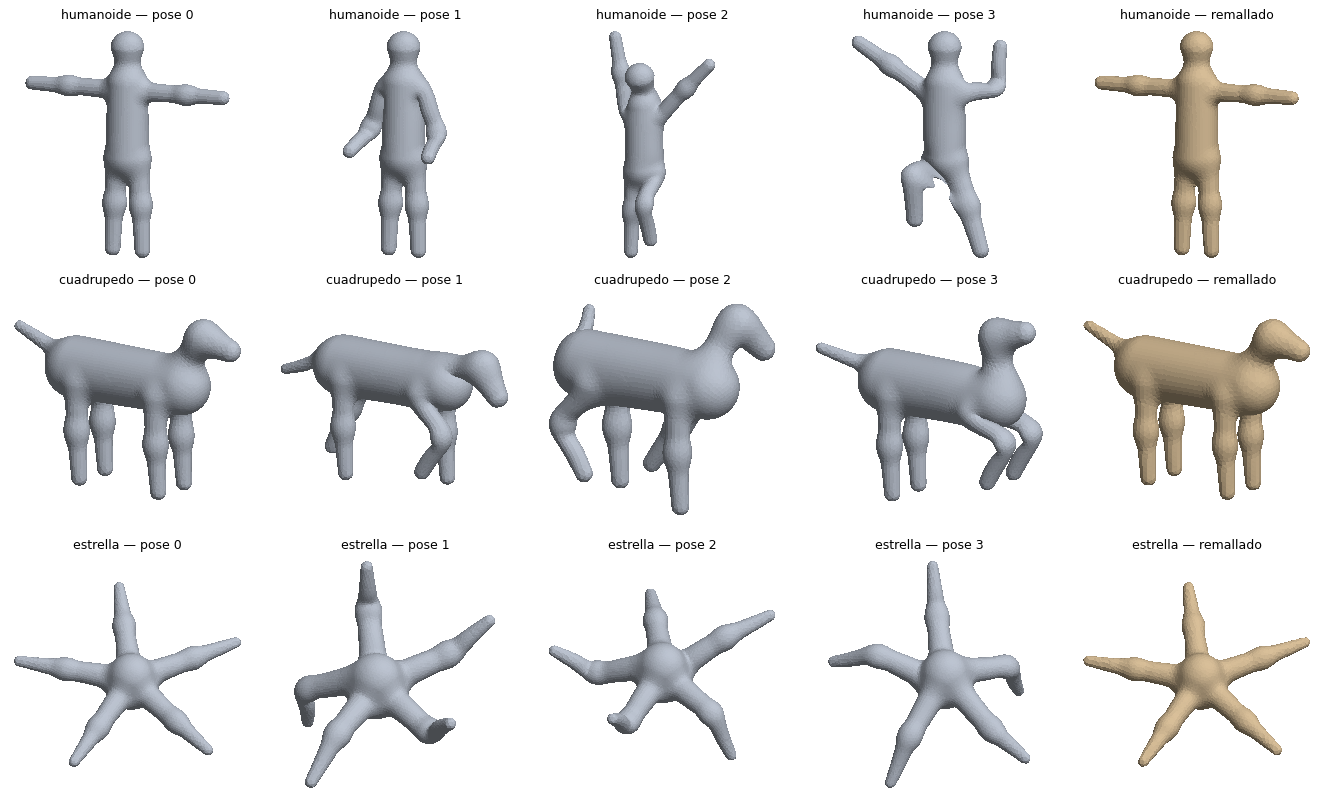

In [2]:
t0 = time.time()
DATA = {}          # DATA[clase] = dict(V0, F, poses=[V_pose...], remesh=(V,F), bones)
rng = np.random.default_rng(0)
for cls, make in BONES.items():
    bones = make()
    V0, F = mesh_from_bones(bones, h=0.035)
    poses = [pose_mesh(V0, bones, p) for p in POSES[cls]]
    remesh = mesh_from_bones(bones, h=0.045)
    DATA[cls] = dict(F=F, poses=poses, remesh=remesh, bones=bones)
    # distorsión geodésica entre pares (relativa), pose de reposo vs. el resto
    src = rng.choice(len(V0), 40, replace=False)
    G0 = geodesics_from(V0, F, src); m = G0 > 0.5
    dist = [np.median(np.abs(geodesics_from(Vp, F, src)[m] / G0[m] - 1)) for Vp in poses[1:]]
    print(f'{cls:11s} {len(V0):5d} vért., χ = {euler_characteristic(V0, F)}, '
          f'remallado: {len(remesh[0])} vért. | distorsión geodésica mediana por pose: '
          + ', '.join(f'{100*d:.1f}%' for d in dist))
print(f'({time.time()-t0:.1f} s)')

fig, axs = plt.subplots(3, 5, figsize=(15, 9))
for r, cls in enumerate(DATA):
    d = DATA[cls]
    for c, Vp in enumerate(d['poses']):
        render(axs[r, c], Vp, d['F'], view=VIEWS[cls], title=f'{cls} — pose {c}')
    render(axs[r, 4], *d['remesh'], view=VIEWS[cls], color=(0.85, 0.75, 0.6), title=f'{cls} — remallado')
plt.tight_layout(); plt.show()

Las tres clases tienen género 0 ($\chi=2$) y la distorsión geodésica mediana entre poses es de
unos pocos por ciento. Esa es la "casi isometría" con la que trabajaremos: los descriptores
intrínsecos deberían cambiar **poco** entre columnas y **mucho** entre filas.

---
# Bloque 1 — Espectro del Laplaciano y ShapeDNA (40 min)

## 1.1 El problema de valores propios generalizado

En el continuo, el Laplaciano de una superficie compacta tiene un espectro discreto
$\Delta\phi_k=\lambda_k\phi_k$ con $0=\lambda_1\le\lambda_2\le\dots$ y eigenfunciones
ortonormales en $L^2(\mathcal X)$. Al discretizar con elementos finitos lineales,
$\Delta\approx\mathbf M^{-1}\mathbf L$ y el problema queda

$$\mathbf L\,\boldsymbol\phi = \lambda\,\mathbf M\,\boldsymbol\phi .$$

Tres observaciones prácticas:

* $\mathbf M^{-1}\mathbf L$ **no es simétrica**, pero $\mathbf L$ y $\mathbf M$ sí lo son (y
  $\mathbf M\succ 0$). Por eso se resuelve el problema **generalizado** simétrico: valores propios
  reales y eigenvectores $\mathbf M$-ortonormales, $\boldsymbol\Phi^\top\mathbf M\boldsymbol\Phi=\mathbf I$.
  Es la versión discreta de $\langle\phi_i,\phi_j\rangle_{L^2(\mathcal X)}=\delta_{ij}$:
  el producto interno de funciones es $\langle f,g\rangle_{\mathbf M}=\mathbf f^\top\mathbf M\mathbf g$.
* Queremos los $k$ valores propios **más pequeños** de una matriz rala con $n\sim 5000$.
  ARPACK (`scipy.sparse.linalg.eigsh`) converge mal hacia los extremos pequeños, pero con
  **shift-invert** (`sigma` cerca de 0) busca los valores más grandes de
  $(\mathbf L-\sigma\mathbf M)^{-1}\mathbf M$, que son justamente los $\lambda$ más cercanos a $\sigma$.
* Como $\mathbf L$ es singular ($\mathbf L\mathbf 1=\mathbf 0$), usamos un $\sigma$ ligeramente
  **negativo** para que $\mathbf L-\sigma\mathbf M$ sea invertible.

### ✏️ Ejercicio 1 — Espectro del Laplaciano

Implementa `laplace_spectrum(V, F, k)` que devuelva los `k` valores propios más pequeños
(ordenados de menor a mayor) y sus eigenvectores $\mathbf M$-normalizados, además de
$\mathbf L$ y $\mathbf M$.

*Pistas:* `cotan_laplacian`, `mass_matrix` y `sla.eigsh(L, k=k, M=M, sigma=..., which='LM')`.
`eigsh` ya devuelve eigenvectores $\mathbf M$-ortonormales, pero **no** garantiza el orden.
Por redondeo $\lambda_1$ puede salir $-10^{-12}$: recórtalo a 0.

Los tests usan la esfera unitaria, cuyo espectro conocemos: $\lambda=\ell(\ell+1)$ con
multiplicidad $2\ell+1$, es decir $0,\;2,2,2,\;6\times 5,\;12\times 7,\dots$

In [3]:
# Ejercicio 1 — solución
def laplace_spectrum(V, F, k):
    '''Devuelve lam (k,), Phi (n,k), L, M con L Phi = M Phi diag(lam), Phi^T M Phi = I.'''
    L = cotan_laplacian(V, F)
    M = mass_matrix(V, F)
    lam, Phi = sla.eigsh(L, k=k, M=M, sigma=-1e-8, which='LM')
    order = np.argsort(lam)
    lam, Phi = lam[order], Phi[:, order]
    lam[0] = max(lam[0], 0.0)
    return lam, Phi, L, M

In [4]:
# Tests del Ejercicio 1
Vs, Fs = icosphere(4)
t0 = time.time(); lam_s, Phi_s, L_s, M_s = laplace_spectrum(Vs, Fs, 25); print(f'eigsh: {time.time()-t0:.2f} s')
ref = np.array([l * (l + 1) for l in range(5) for _ in range(2 * l + 1)])[:25]
print('esfera, discreto :', lam_s[:16].round(3))
print('esfera, continuo :', ref[:16].astype(float))
assert np.all(np.diff(lam_s) >= -1e-9), 'los valores propios deben venir ordenados'
assert abs(lam_s[0]) < 1e-8, 'lambda_1 debe ser 0'
assert np.allclose(lam_s[1:25], ref[1:25], rtol=0.02), 'el espectro de la esfera debe ser l(l+1)'
G = Phi_s.T @ M_s @ Phi_s
assert np.allclose(G, np.eye(25), atol=1e-6), 'Phi debe ser M-ortonormal'
assert np.std(Phi_s[:, 0]) / abs(np.mean(Phi_s[:, 0])) < 1e-6, 'phi_1 debe ser constante'
assert np.isclose(abs(Phi_s[0, 0]), 1 / np.sqrt(M_s.diagonal().sum())), 'phi_1 = 1/sqrt(Área)'
print('✅ Ejercicio 1 correcto')

eigsh: 0.45 s
esfera, discreto : [ 0.     2.     2.     2.     5.991  5.991  5.991  5.991  5.991 11.957 11.957 11.957 11.957 11.958 11.958 11.958]
esfera, continuo : [ 0.  2.  2.  2.  6.  6.  6.  6.  6. 12. 12. 12. 12. 12. 12. 12.]
✅ Ejercicio 1 correcto


Observa que $\phi_1 = 1/\sqrt{A}$: la constante normalizada. Su coeficiente de Fourier
$\langle f,\phi_1\rangle$ es la integral de $f$ dividida por $\sqrt A$. Esto volverá en la
ecuación del calor (conservación de la energía).

## 1.2 ShapeDNA (Reuter, Wolter y Peinecke, 2006)

El espectro $\{\lambda_k\}$ sólo depende de la **métrica** de la superficie, así que es
invariante a isometrías, a la triangulación y a la posición en el espacio. Es un "código
genético" de la forma: la **ShapeDNA** (slide 35).

Falta un detalle: la escala. Si multiplicamos la superficie por $s$, las distancias crecen
$s$ veces, el área $s^2$ veces y los valores propios se dividen por $s^2$. La normalización
estándar es multiplicar por el área: $\tilde\lambda_k = A\,\lambda_k$.

La **ley de Weyl** dice cuánto debería valer: en una superficie,
$$\lambda_k \sim \frac{4\pi k}{A}\quad (k\to\infty)\qquad\Longrightarrow\qquad \tilde\lambda_k\approx 4\pi k .$$
O sea, el espectro normalizado crece linealmente con pendiente universal $4\pi$, y la
información de la forma está en **cómo se desvía** de esa recta, sobre todo en los primeros
valores.

### ✏️ Ejercicio 2 — ShapeDNA normalizada por área

Implementa `shapedna(V, F, k)` que devuelva el vector de $k$ valores propios normalizados
$\tilde\lambda_j = A\,\lambda_j$ (incluyendo $\tilde\lambda_1=0$). Usa tu `laplace_spectrum`
y calcula $A$ como la traza de $\mathbf M$.

Los tests verifican invariancia a escala y a movimientos rígidos, y la ley de Weyl.

In [5]:
# Ejercicio 2 — solución
def shapedna(V, F, k=100):
    lam, _, _, M = laplace_spectrum(V, F, k)
    return lam * M.diagonal().sum()

In [6]:
# Tests del Ejercicio 2
Vh, Fh = DATA['humanoide']['poses'][0], DATA['humanoide']['F']
s0 = shapedna(Vh, Fh, 100)
Q, _ = np.linalg.qr(np.random.default_rng(1).normal(size=(3, 3)))
s1 = shapedna(2.5 * Vh @ Q.T + np.array([3., -1., 7.]), Fh, 100)
print('ShapeDNA humanoide (primeros 8):', s0[:8].round(2))
assert np.allclose(s0, s1, rtol=1e-6, atol=1e-6), 'debe ser invariante a escala, rotación y traslación'
weyl = s0[49:] / (4 * np.pi * np.arange(50, 101))
print(f'Weyl: A·λ_k / (4πk) para k=50..100 → media {weyl.mean():.3f}')
assert 0.85 < weyl.mean() < 1.15, 'A·λ_k debería crecer como 4πk'
print('✅ Ejercicio 2 correcto')

ShapeDNA humanoide (primeros 8): [ 0.    5.62  9.52 14.58 17.02 27.93 57.35 72.06]
Weyl: A·λ_k / (4πk) para k=50..100 → media 0.972
✅ Ejercicio 2 correcto


Ahora calculamos la ShapeDNA de las 15 mallas del Bloque 0 (12 poses + 3 remallados) y la
dibujamos como en la slide 35. Toma unos 15 segundos.

15 espectros en 17.9 s


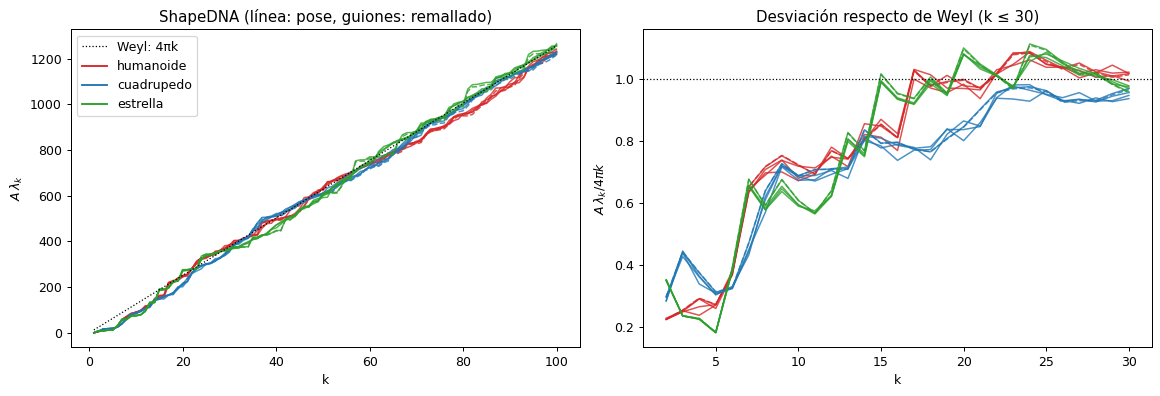

In [7]:
KDNA = 100
names, labels, DNA = [], [], []
t0 = time.time()
for cls, d in DATA.items():
    for j, Vp in enumerate(d['poses']):
        names.append(f'{cls}-p{j}'); labels.append(cls); DNA.append(shapedna(Vp, d['F'], KDNA))
    names.append(f'{cls}-remallado'); labels.append(cls); DNA.append(shapedna(*d['remesh'], KDNA))
DNA = np.array(DNA); labels = np.array(labels)
print(f'{len(DNA)} espectros en {time.time()-t0:.1f} s')

colors = {'humanoide': 'tab:red', 'cuadrupedo': 'tab:blue', 'estrella': 'tab:green'}
k = np.arange(1, KDNA + 1)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for s, lab, nm in zip(DNA, labels, names):
    ls = '--' if 'remallado' in nm else '-'
    axs[0].plot(k, s, ls, color=colors[lab], lw=1.2, alpha=.8)
    axs[1].plot(k[1:30], s[1:30] / (4 * np.pi * k[1:30]), ls, color=colors[lab], lw=1.2, alpha=.8)
axs[0].plot(k, 4 * np.pi * k, 'k:', lw=1, label='Weyl: 4πk')
axs[0].set(xlabel='k', ylabel=r'$A\,\lambda_k$', title='ShapeDNA (línea: pose, guiones: remallado)')
for c, col in colors.items(): axs[0].plot([], [], color=col, label=c)
axs[0].legend()
axs[1].axhline(1, color='k', ls=':', lw=1)
axs[1].set(xlabel='k', ylabel=r'$A\,\lambda_k / 4\pi k$', title='Desviación respecto de Weyl (k ≤ 30)')
plt.tight_layout(); plt.show()

A escala completa (izquierda) las curvas casi se superponen: es la ley de Weyl. La
información está en la desviación (derecha): las 5 curvas de cada clase (4 poses + el
remallado) forman un haz, y los haces de distintas clases se separan.

Fíjate en la **estrella**: sus valores propios vienen **en pares** ($\tilde\lambda_2=\tilde\lambda_3$,
$\tilde\lambda_4=\tilde\lambda_5$, …). La simetría rotacional de orden 5 hace que los
espacios propios tengan dimensión 2. Lo veremos de nuevo en el Bloque 2, porque una
eigenfunción dentro de un espacio propio múltiple **no está bien definida**.

## 1.3 Comparar formas con ShapeDNA

Para comparar dos espectros normalizados necesitamos una distancia. Por Weyl,
$\tilde\lambda_k$ crece como $k$, así que si usáramos la distancia euclidiana directa los
valores altos (los más ruidosos) dominarían. Una opción simple es dividir cada término por $k$:

$$d(\mathcal X,\mathcal Y) = \Big(\sum_{k\ge 2} \Big(\frac{\tilde\lambda_k^{\mathcal X}-\tilde\lambda_k^{\mathcal Y}}{k}\Big)^2\Big)^{1/2}.$$

### ✏️ Ejercicio 3 — Distancia entre ShapeDNAs y recuperación

1. Implementa `dna_distance_matrix(S)` que reciba una matriz `S` de forma `(m, K)` (una
   ShapeDNA por fila) y devuelva la matriz `(m, m)` de distancias de arriba (ignora $k=1$).
   Hazlo vectorizado con *broadcasting*.
2. Implementa `nn_accuracy(D, labels)`: para cada forma busca su vecino más cercano
   **distinto de sí misma** y devuelve la fracción de veces en que comparten etiqueta.

In [8]:
# Ejercicio 3 — solución
def dna_distance_matrix(S):
    k = np.arange(1, S.shape[1] + 1)
    diff = (S[:, None, 1:] - S[None, :, 1:]) / k[1:]
    return np.sqrt((diff ** 2).sum(-1))

def nn_accuracy(D, labels):
    D = D.copy(); np.fill_diagonal(D, np.inf)
    return np.mean(labels[D.argmin(1)] == labels)

In [9]:
# Tests del Ejercicio 3
D_dna = dna_distance_matrix(DNA)
assert D_dna.shape == (15, 15) and np.allclose(D_dna, D_dna.T) and np.allclose(np.diag(D_dna), 0)
same = labels[:, None] == labels[None, :]
intra = D_dna[same & ~np.eye(15, dtype=bool)].mean(); inter = D_dna[~same].mean()
acc = nn_accuracy(D_dna, labels)
print(f'distancia media intra-clase {intra:.2f} | inter-clase {inter:.2f} | razón {inter/intra:.1f}')
print(f'exactitud 1-NN: {acc:.2f}')
assert acc == 1.0, 'cada forma debería tener como vecino más cercano a una de su clase'
assert inter / intra > 2.5
print('✅ Ejercicio 3 correcto')

distancia media intra-clase 2.16 | inter-clase 8.98 | razón 4.2
exactitud 1-NN: 1.00
✅ Ejercicio 3 correcto


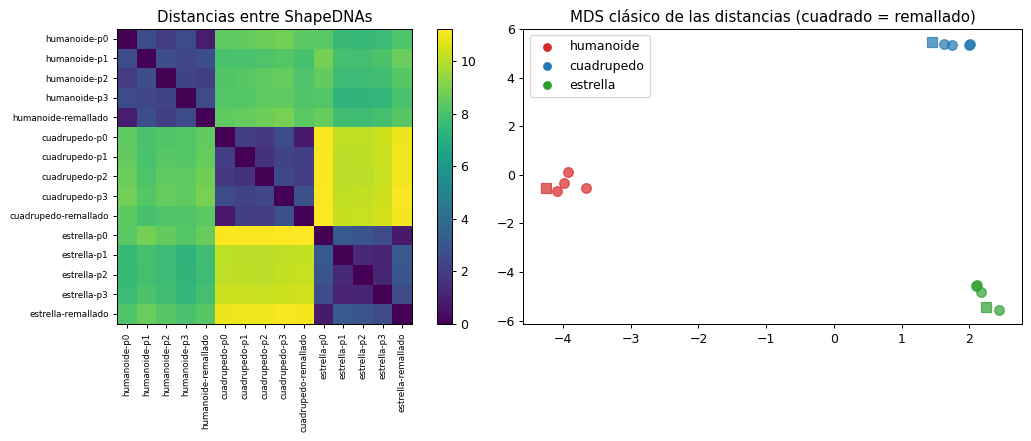

In [10]:
# Matriz de distancias y un embedding 2D por MDS clásico
D = D_dna
J = np.eye(len(D)) - 1 / len(D); B = -0.5 * J @ (D ** 2) @ J
w, U = np.linalg.eigh(B); Y = U[:, -2:] * np.sqrt(np.maximum(w[-2:], 0))
fig, axs = plt.subplots(1, 2, figsize=(13, 5))
im = axs[0].imshow(D, cmap='viridis'); plt.colorbar(im, ax=axs[0], fraction=0.046)
axs[0].set_xticks(range(15)); axs[0].set_xticklabels(names, rotation=90, fontsize=7)
axs[0].set_yticks(range(15)); axs[0].set_yticklabels(names, fontsize=7)
axs[0].set_title('Distancias entre ShapeDNAs')
for (x, y), nm, lab in zip(Y, names, labels):
    axs[1].scatter(x, y, s=60, color=colors[lab], marker='s' if 'remallado' in nm else 'o', alpha=.7)
for c, col in colors.items(): axs[1].scatter([], [], color=col, label=c)
axs[1].legend()
axs[1].set_title('MDS clásico de las distancias (cuadrado = remallado)')
plt.tight_layout(); plt.show()

### Lo que ShapeDNA no ve (y lo que ve demasiado)

**Isometrías y simetrías.** Por construcción, dos formas isométricas son indistinguibles.
Peor aún: existen formas **isoespectrales que no son isométricas** (Gordon, Webb y Wolpert,
1992, respondieron que *no* se puede "oír la forma de un tambor"). En la práctica son raras.

**Topología.** El Laplaciano es intrínseco, así que un cambio de **conectividad** de la
superficie, por ejemplo una mano que toca la cadera y se fusiona con ella, cambia la métrica
de forma global. En escaneos reales esto pasa a menudo (*ruido topológico*). Lo probamos:
remallamos el humanoide en dos poses casi iguales, una con la mano **cerca** de la cadera y
otra con la mano **tocándola**.

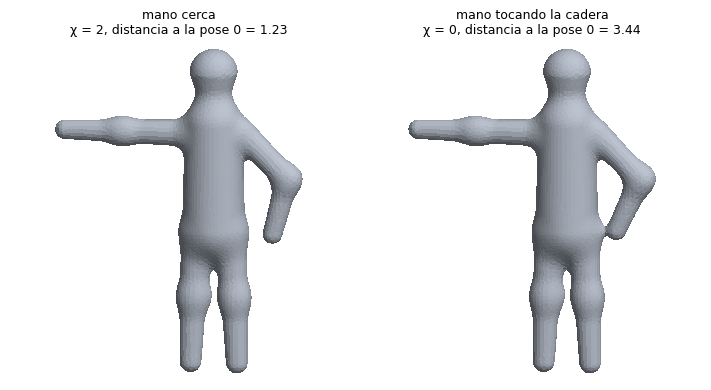

Referencia: distancia intra-clase media 2.16, inter-clase media 8.98


In [11]:
bones_h = DATA['humanoide']['bones']
s_ref = DNA[names.index('humanoide-p0')]
fig, axs = plt.subplots(1, 2, figsize=(8, 4.5))
for ax, (fore, txt) in zip(axs, [(-60, 'mano cerca'), (-70, 'mano tocando la cadera')]):
    Vc, Fc = mesh_from_bones(posed_bones(bones_h, {'armL': (Z, -45), 'foreL': (Z, fore)}))
    sc = shapedna(Vc, Fc, KDNA)
    d = dna_distance_matrix(np.stack([s_ref, sc]))[0, 1]
    render(ax, Vc, Fc, view=(10, -10),
           title=f'{txt}\nχ = {euler_characteristic(Vc, Fc)}, distancia a la pose 0 = {d:.2f}')
plt.tight_layout(); plt.show()
print(f'Referencia: distancia intra-clase media {intra:.2f}, inter-clase media {inter:.2f}')

Con la mano cerca la distancia es del orden de la variación entre poses. Al tocarse, la
superficie pasa a tener **género 1** ($\chi=0$: aparece un asa) y la distancia se triplica,
aunque la forma "se ve" casi igual. Ninguna deformación isométrica puede crear un asa, así
que el espectro tiene razón en considerarla otra superficie, pero en un escaneo real eso
suele ser ruido.

> **Para discutir:** ¿qué otras perturbaciones cambian mucho el espectro con poco cambio visual?
> ¿Y cuáles cambian mucho la forma visual con poco cambio espectral?

---
# Bloque 2 — Eigenfunciones y análisis de Fourier en variedades (30 min)

## 2.1 Fourier clásico = eigenfunciones del Laplaciano

En $[-\pi,\pi]$ periódico, $-\frac{d^2}{dx^2}e^{ikx}=k^2e^{ikx}$: la base de Fourier está formada
por eigenfunciones del Laplaciano y la "frecuencia" es $\sqrt{\lambda}$ (slide 39). Lo comprobamos
con el Laplaciano de un **grafo ciclo** (la versión discreta de un círculo).

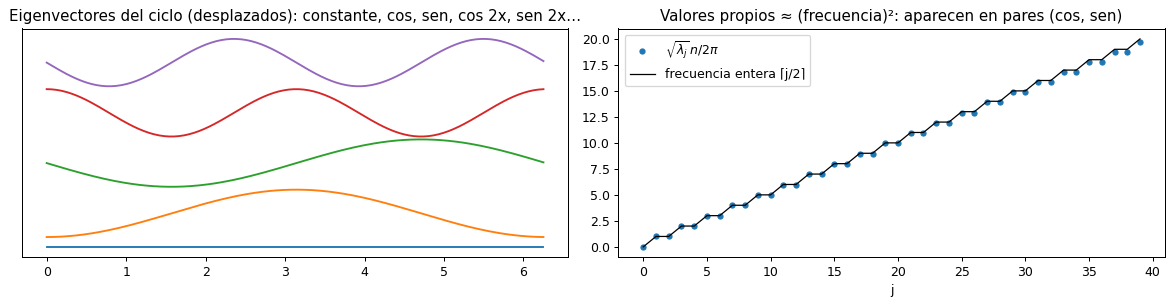

In [12]:
n = 200
Lc = 2 * np.eye(n) - np.roll(np.eye(n), 1, 0) - np.roll(np.eye(n), -1, 0)
lam_c, U_c = np.linalg.eigh(Lc)
xg = np.arange(n) * 2 * np.pi / n
fig, axs = plt.subplots(1, 2, figsize=(13, 3.5))
for j in range(5):
    axs[0].plot(xg, U_c[:, j] * np.sqrt(n) + 3 * j, lw=1.5)
axs[0].set(title='Eigenvectores del ciclo (desplazados): constante, cos, sen, cos 2x, sen 2x…', yticks=[])
kk = np.arange(n)
axs[1].plot(np.sqrt(np.abs(lam_c[:40])) * n / (2 * np.pi), 'o', ms=4, label=r'$\sqrt{\lambda_j}\,n/2\pi$')
axs[1].plot(np.ceil(kk[:40] / 2), 'k-', lw=1, label='frecuencia entera ⌈j/2⌉')
axs[1].set(xlabel='j', title='Valores propios ≈ (frecuencia)²: aparecen en pares (cos, sen)'); axs[1].legend()
plt.tight_layout(); plt.show()

Igual que la estrella del Bloque 1, el círculo tiene valores propios **dobles**: $\cos kx$ y
$\sin kx$ comparten frecuencia, y cualquier rotación de ese par también es eigenfunción.

## 2.2 Eigenfunciones del Laplaciano en una superficie

En una superficie no hay senos ni cosenos, pero las eigenfunciones $\phi_k$ hacen el mismo
papel: $\phi_2$ es la "onda" más lenta posible sobre la forma, $\phi_3$ la siguiente
ortogonal, etc. Al ser intrínsecas, deberían ser **las mismas en cualquier pose** (slides 36–37).

Calculamos 200 pares propios del humanoide en las poses 0 y 3 (≈ 10 s).

7.4 s | λ_2..λ_6 pose A: [1.154 1.954 2.993 3.495 5.733] | pose B: [1.174 1.948 2.448 3.486 5.886]


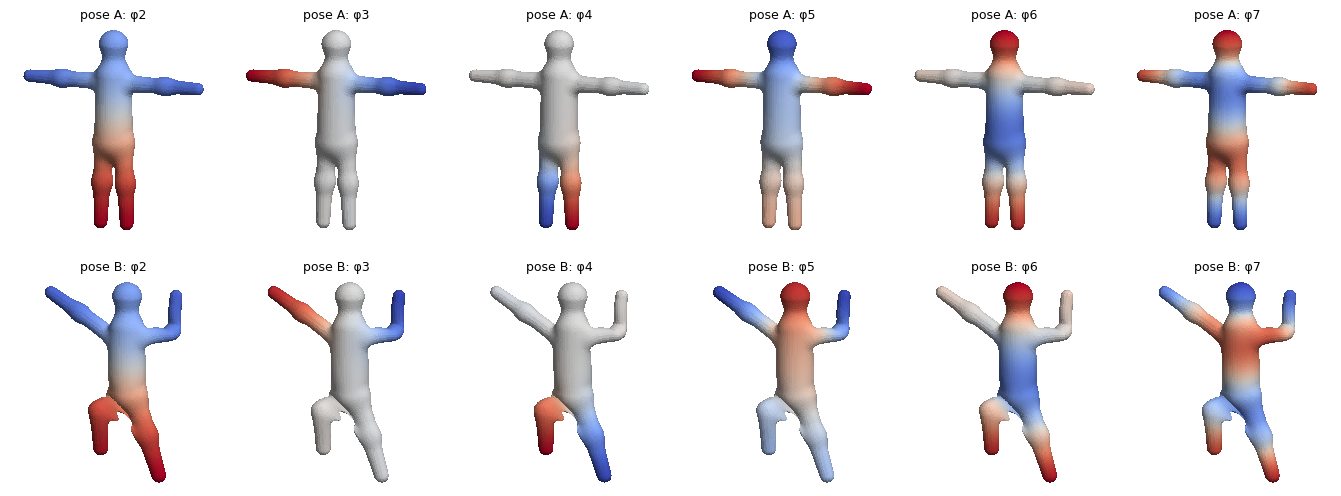

In [13]:
KH = 200
FH = DATA['humanoide']['F']
VA, VB = DATA['humanoide']['poses'][0], DATA['humanoide']['poses'][3]
t0 = time.time()
lamA, PhiA, LA, MA = laplace_spectrum(VA, FH, KH)
lamB, PhiB, LB, MB = laplace_spectrum(VB, FH, KH)
AREA_H = MA.diagonal().sum()
print(f'{time.time()-t0:.1f} s | λ_2..λ_6 pose A: {lamA[1:6].round(3)} | pose B: {lamB[1:6].round(3)}')

fig, axs = plt.subplots(2, 6, figsize=(15, 6))
for j in range(6):
    render(axs[0, j], VA, FH, PhiA[:, j + 1], sym=True, view=VIEWS['humanoide'], title=f'pose A: φ{j+2}')
    render(axs[1, j], VB, FH, PhiB[:, j + 1], sym=True, view=VIEWS['humanoide'], title=f'pose B: φ{j+2}')
plt.tight_layout(); plt.show()

Las eigenfunciones bajas separan la forma en sus partes más largas (piernas contra brazos, brazo
izquierdo contra derecho, …) y se ven iguales en ambas poses **salvo, quizá, el signo**: si
$\phi$ es eigenfunción, $-\phi$ también lo es, y el solver elige uno al azar.

Para medir cuán parecidas son, usamos la correspondencia por índice: proyectamos cada
$\phi^B_j$ sobre cada $\phi^A_i$,
$$C_{ij} = \langle \phi^A_i, \phi^B_j\rangle_{\mathbf M_A} = (\boldsymbol\Phi_A^\top\mathbf M_A\boldsymbol\Phi_B)_{ij}.$$
Si las bases fueran idénticas, $\mathbf C$ sería diagonal con $\pm1$. Esta matriz es, de hecho,
un **mapa funcional** (Ovsjanikov et al., 2012): la representación en bases espectrales de una
correspondencia entre formas.

### ✏️ Ejercicio 4 — Correlación entre bases espectrales y corrección de signo

1. `eigenbasis_correlation(PhiA, PhiB, MA)` devuelve $\mathbf C=\boldsymbol\Phi_A^\top\mathbf M_A\boldsymbol\Phi_B$.
2. `sign_fix(C)` devuelve el vector de signos $s_j=\operatorname{sign}(C_{jj})$ (usa $+1$ si $C_{jj}=0$),
   de modo que `PhiB * s` quede alineada con `PhiA`.

In [14]:
# Ejercicio 4 — solución
def eigenbasis_correlation(PhiA, PhiB, MA):
    return PhiA.T @ (MA @ PhiB)

def sign_fix(C):
    s = np.sign(np.diag(C))
    s[s == 0] = 1
    return s

In [15]:
# Tests del Ejercicio 4
C_AB = eigenbasis_correlation(PhiA, PhiB, MA)
s_AB = sign_fix(C_AB)
assert C_AB.shape == (KH, KH)
assert np.allclose(eigenbasis_correlation(PhiA, PhiA, MA), np.eye(KH), atol=1e-6)
print('|C_jj|, j = 1..12:', np.abs(np.diag(C_AB))[:12].round(2))
assert np.all(np.abs(np.diag(C_AB))[:8] > 0.95), 'las primeras eigenfunciones deberían coincidir'
err = [np.sqrt(((PhiA[:, j] - s_AB[j] * PhiB[:, j]) ** 2) @ MA.diagonal()) for j in range(8)]
print('‖φ^A_j − s_j φ^B_j‖_M tras alinear signos:', np.round(err, 3))
assert max(err) < 0.3
print('✅ Ejercicio 4 correcto')

|C_jj|, j = 1..12: [1.   1.   1.01 0.98 1.   0.99 0.99 0.99 0.2  0.21 0.87 0.92]
‖φ^A_j − s_j φ^B_j‖_M tras alinear signos: [0.002 0.036 0.043 0.106 0.035 0.078 0.097 0.142]
✅ Ejercicio 4 correcto


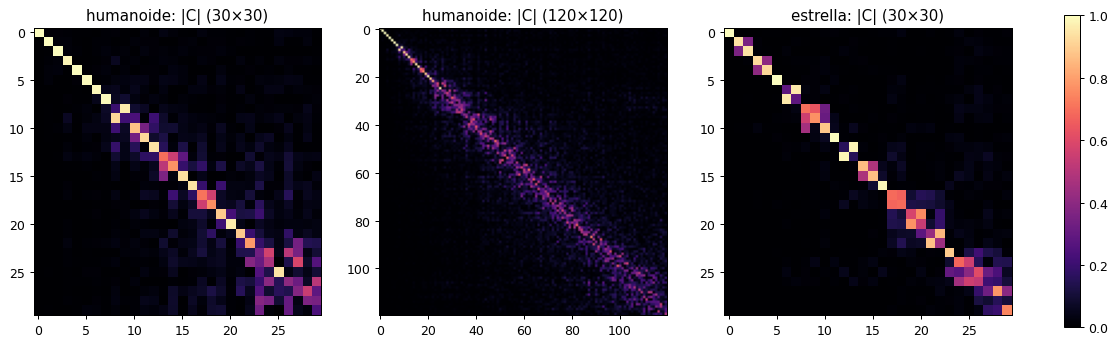

humanoide, valores propios 9–12: [17.474 18.62  19.692 23.799] → casi degenerados
estrella, valores propios 2–7:   [ 1.643  1.644  2.116  2.117  5.478 11.076] → pares


In [16]:
# Matrices C: humanoide (A vs B) y estrella (pose 0 vs pose 1)
dS = DATA['estrella']
lamS0, PhiS0, _, MS0 = laplace_spectrum(dS['poses'][0], dS['F'], 30)
lamS1, PhiS1, _, _ = laplace_spectrum(dS['poses'][1], dS['F'], 30)
C_S = eigenbasis_correlation(PhiS0, PhiS1, MS0)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, Cm, ttl in [(axs[0], C_AB[:30, :30], 'humanoide: |C| (30×30)'),
                    (axs[1], C_AB[:120, :120], 'humanoide: |C| (120×120)'),
                    (axs[2], C_S, 'estrella: |C| (30×30)')]:
    im = ax.imshow(np.abs(Cm), cmap='magma', vmin=0, vmax=1); ax.set_title(ttl)
plt.colorbar(im, ax=axs, fraction=0.015); plt.show()
print('humanoide, valores propios 9–12:', lamA[8:12].round(3), '→ casi degenerados')
print('estrella, valores propios 2–7:  ', lamS0[1:7].round(3), '→ pares')

Tres fenómenos que hay que conocer antes de usar eigenfunciones para comparar formas:

* **Signo**: lo arreglamos con `sign_fix` porque conocíamos la correspondencia. Sin ella hay
  que usar heurísticas o descriptores que no dependan del signo (los de los bloques 3–5).
* **Cruces**: si dos valores propios están muy cerca (aquí $\lambda_9\approx\lambda_{10}$), una
  pequeña deformación puede **intercambiar** su orden o mezclarlos: aparece un bloque $2\times2$
  fuera de la diagonal.
* **Multiplicidad**: en la estrella los espacios propios son de dimensión 2 y la base dentro de
  cada uno es arbitraria: $\mathbf C$ es diagonal **por bloques**, con rotaciones dentro de cada bloque.
* **Frecuencias altas**: la diagonal se va difuminando; la deformación no es exactamente
  isométrica y las eigenfunciones altas son las más sensibles.

## 2.3 Transformada de Fourier en una variedad

Una función $f:\mathcal X\to\mathbb R$ se escribe en la base de eigenfunciones (slide 40):
$$f=\sum_{k\ge1}\hat f_k\,\phi_k,\qquad \hat f_k=\langle f,\phi_k\rangle_{L^2(\mathcal X)}\approx(\boldsymbol\Phi^\top\mathbf M\mathbf f)_k .$$
Truncar la suma a los primeros $m$ términos es un **filtro pasa-bajos**. La identidad de
Parseval, $\|f\|^2_{\mathbf M}=\sum_k\hat f_k^2$, vale cuando $f$ está en el espacio generado.

### ✏️ Ejercicio 5 — Transformada de Fourier espectral

1. `fourier(f, Phi, M)` devuelve los coeficientes $\hat{\mathbf f}=\boldsymbol\Phi^\top\mathbf M\mathbf f$
   (debe funcionar también si `f` es una matriz `(n, d)`, por ejemplo las coordenadas).
2. `inverse_fourier(fh, Phi, m)` reconstruye con los primeros `m` coeficientes.

In [17]:
# Ejercicio 5 — solución
def fourier(f, Phi, M):
    return Phi.T @ (M @ f)

def inverse_fourier(fh, Phi, m):
    return Phi[:, :m] @ fh[:m]

In [18]:
# Tests del Ejercicio 5
g = PhiA[:, :40] @ np.random.default_rng(0).normal(size=40)        # función de banda limitada
gh = fourier(g, PhiA, MA)
assert np.allclose(gh[:40], np.linalg.lstsq(PhiA[:, :40], g, rcond=None)[0], atol=1e-6)
assert np.isclose(g @ MA @ g, (gh ** 2).sum()), 'Parseval'
assert np.allclose(inverse_fourier(gh, PhiA, 40), g, atol=1e-8), 'reconstrucción exacta'
assert fourier(VA, PhiA, MA).shape == (KH, 3)
print('✅ Ejercicio 5 correcto')

✅ Ejercicio 5 correcto


Comparamos dos funciones sobre el humanoide: una **suave** (una combinación de las
coordenadas) y una **discontinua** (indicadora del brazo izquierdo, parecida a la $f$ de la
slide 40). El error relativo de la reconstrucción con $m$ términos decae muy distinto.

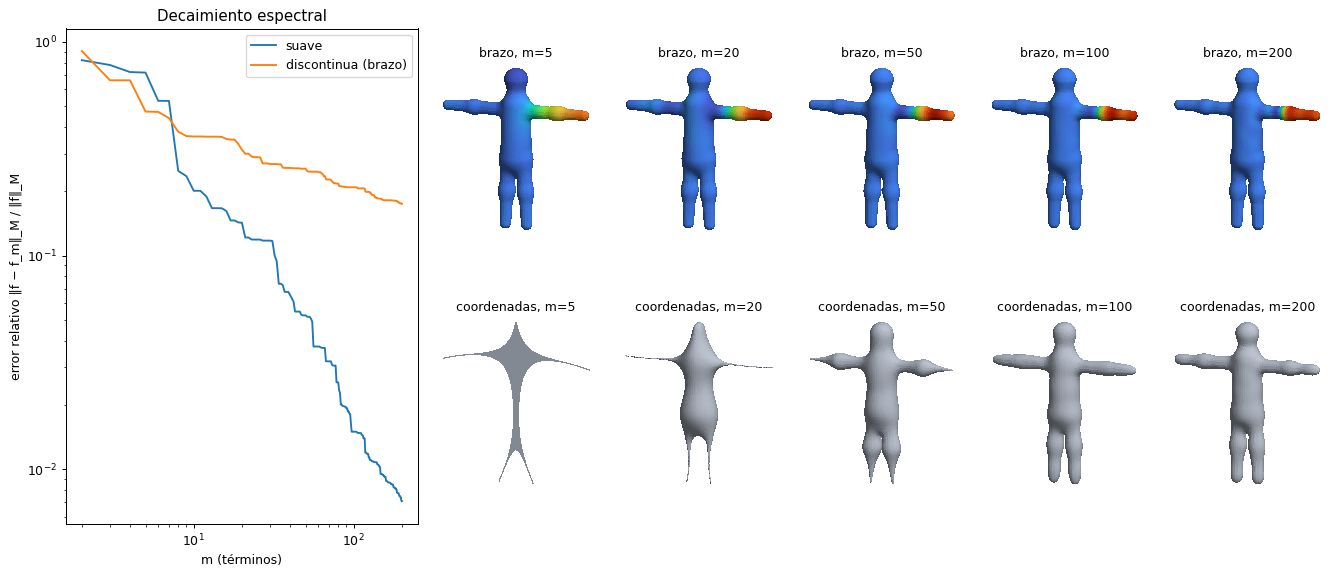

In [19]:
f_smooth = VA[:, 1] ** 2 + np.sin(3 * VA[:, 0])
f_step = (VA[:, 0] > 0.7).astype(float)
ms = [5, 10, 20, 50, 100, 200]
fig = plt.figure(figsize=(15, 6.5)); gs = fig.add_gridspec(2, 7)
ax = fig.add_subplot(gs[:, :2])
for f, lbl in [(f_smooth, 'suave'), (f_step, 'discontinua (brazo)')]:
    fh = fourier(f, PhiA, MA)
    e = [np.sqrt((r := inverse_fourier(fh, PhiA, m) - f) @ MA @ r / (f @ MA @ f)) for m in range(2, KH + 1)]
    ax.loglog(range(2, KH + 1), e, label=lbl)
ax.set(xlabel='m (términos)', ylabel='error relativo ‖f − f_m‖_M / ‖f‖_M', title='Decaimiento espectral'); ax.legend()
fh = fourier(f_step, PhiA, MA)
for j, m in enumerate([5, 20, 50, 100, 200]):
    render(fig.add_subplot(gs[0, 2 + j]), VA, FH, inverse_fourier(fh, PhiA, m), cmap='turbo',
           vmin=-0.25, vmax=1.25, view=VIEWS['humanoide'], title=f'brazo, m={m}')
    Xm = inverse_fourier(fourier(VA, PhiA, MA), PhiA, m)
    render(fig.add_subplot(gs[1, 2 + j]), Xm, FH, view=VIEWS['humanoide'], title=f'coordenadas, m={m}')
plt.tight_layout(); plt.show()

* La función suave converge rápido; la discontinua lento y con **oscilaciones de Gibbs**
  (valores $<0$ y $>1$ a ambos lados del corte, cerca del codo), igual que en Fourier clásico.
* Abajo filtramos las **coordenadas** $(x,y,z)$ como tres funciones: con 5 términos queda un
  "esqueleto" de la pose, y con más términos aparece el detalle. Es la idea de *manifold
  harmonics* (Vallet y Lévy, 2008) que usamos en la Clase 4 para suavizar.

---
# Bloque 3 — Ecuación del calor y kernel de calor (30 min)

## 3.1 Difusión de calor en una variedad

Fourier (1822) introdujo su serie justamente para resolver la ecuación del calor (slides 41–46):
$$\begin{cases} f_t(x,t) = -\Delta f(x,t)\\ f(x,0)=f_0(x)\end{cases}$$
Como $\Delta\phi_k=\lambda_k\phi_k$, cada componente de Fourier evoluciona de forma independiente
y decae exponencialmente según su frecuencia:
$$f(x,t)=e^{-t\Delta}f_0(x)=\sum_{k\ge1}\langle f_0,\phi_k\rangle\,e^{-t\lambda_k}\,\phi_k(x).$$

En forma matricial: $\mathbf f(t)=\boldsymbol\Phi\,e^{-t\boldsymbol\Lambda}\,\boldsymbol\Phi^\top\mathbf M\,\mathbf f_0$.
El operador de calor es un filtro pasa-bajos **suave**, con respuesta $G(\lambda)=e^{-t\lambda}$.
Con 200 eigenfunciones la truncación es despreciable en cuanto $e^{-t\lambda_{200}}\ll1$.

### ✏️ Ejercicio 6 — Difusión de calor espectral

Implementa `heat_diffuse(f0, lam, Phi, M, ts)` que devuelva una matriz `(n, len(ts))` con
$\mathbf f(t)$ para cada tiempo de `ts` (vectoriza: calcula los coeficientes de $f_0$ una sola vez).

Los tests comparan con la solución por pasos de tiempo implícitos (`implicit_heat`, la
misma integración de la Clase 4) y verifican dos propiedades físicas: el calor total
$\int f\,dA=\mathbf 1^\top\mathbf M\mathbf f$ se **conserva**, y para $t\to\infty$ la
temperatura se **uniformiza** en el promedio.

In [20]:
# Ejercicio 6 — solución
def heat_diffuse(f0, lam, Phi, M, ts):
    ts = np.atleast_1d(ts)
    c = Phi.T @ (M @ f0)                       # (K,)
    return Phi @ (np.exp(-np.outer(lam, ts)) * c[:, None])

In [21]:
# Tests del Ejercicio 6
f0 = (VA[:, 0] > 0.9).astype(float)                 # mano/antebrazo izquierdo caliente
ts_test = [0.005, 0.02, 0.1]
Ft = heat_diffuse(f0, lamA, PhiA, MA, ts_test)
assert Ft.shape == (len(VA), 3)
heat0 = f0 @ MA.diagonal()
for j, t in enumerate(ts_test):
    ref = implicit_heat(LA, MA, f0, t, nsteps=200)
    rel = np.linalg.norm(Ft[:, j] - ref) / np.linalg.norm(ref)
    print(f't = {t:<6} | dif. relativa vs. Euler implícito: {rel:.1e} | calor total {Ft[:, j] @ MA.diagonal():.6f} (inicial {heat0:.6f})')
    assert rel < 1e-2
    assert np.isclose(Ft[:, j] @ MA.diagonal(), heat0, rtol=1e-8), 'el calor total debe conservarse'
f_inf = heat_diffuse(f0, lamA, PhiA, MA, [1e3])[:, 0]
assert np.allclose(f_inf, heat0 / AREA_H, atol=1e-8), 'para t grande f → promedio'
print('✅ Ejercicio 6 correcto')

t = 0.005  | dif. relativa vs. Euler implícito: 4.2e-03 | calor total 0.196088 (inicial 0.196088)
t = 0.02   | dif. relativa vs. Euler implícito: 4.0e-04 | calor total 0.196088 (inicial 0.196088)
t = 0.1    | dif. relativa vs. Euler implícito: 1.2e-03 | calor total 0.196088 (inicial 0.196088)
✅ Ejercicio 6 correcto


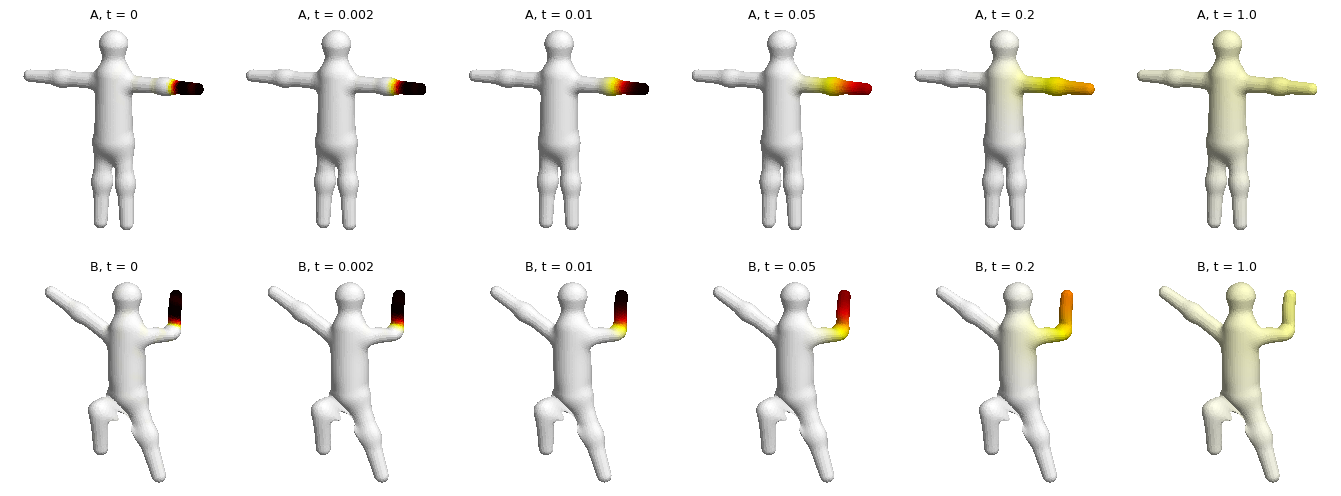

t = 0 sale suavizado: con 200 términos ya no es un escalón exacto (Gibbs del Bloque 2).
Diferencia relativa entre poses a t = 0.05: 0.082


In [22]:
ts_show = [0, 0.002, 0.01, 0.05, 0.2, 1.0]
Ft = heat_diffuse(f0, lamA, PhiA, MA, ts_show)
fig, axs = plt.subplots(2, len(ts_show), figsize=(15, 6))
FtB = heat_diffuse(f0, lamB, PhiB, MB, ts_show)                    # misma f0 (por índice) en la pose B
for j, t in enumerate(ts_show):
    render(axs[0, j], VA, FH, Ft[:, j], cmap='hot_r', vmin=0, vmax=1, view=VIEWS['humanoide'], title=f'A, t = {t}')
    render(axs[1, j], VB, FH, FtB[:, j], cmap='hot_r', vmin=0, vmax=1, view=VIEWS['humanoide'], title=f'B, t = {t}')
plt.tight_layout(); plt.show()
print('t = 0 sale suavizado: con 200 términos ya no es un escalón exacto (Gibbs del Bloque 2).')
print(f'Diferencia relativa entre poses a t = 0.05: {np.linalg.norm(Ft[:, 3] - FtB[:, 3]) / np.linalg.norm(Ft[:, 3]):.3f}')

La difusión es la misma en las dos poses: el calor "no sabe" que el brazo está doblado,
porque sólo depende de la métrica.

## 3.2 El kernel de calor

Reordenando la solución (slide 46):
$$f(x,t)=\int_{\mathcal X} f_0(x')\underbrace{\sum_{k\ge1}e^{-t\lambda_k}\phi_k(x)\phi_k(x')}_{h_t(x,x')}\,dx' .$$
$h_t(x,x')$ es la cantidad de calor que llega a $x'$ en tiempo $t$ si ponemos una unidad de calor
concentrada en $x$ (slide 47). Propiedades:

* **simétrico**: $h_t(x,x')=h_t(x',x)$;
* **conserva masa**: $\int_{\mathcal X}h_t(x,x')\,dx'=1$ (sólo $\phi_1$ tiene integral no nula);
* **positivo** e **invariante a isometrías**;
* **multiescala**: $t$ pequeño ⇒ localizado; $t$ grande ⇒ global, y $h_t\to 1/A$.

### ✏️ Ejercicio 7 — Kernel de calor

Implementa `heat_kernel(lam, Phi, x, t)` que devuelva el vector $h_t(x,\cdot)$ sobre todos los
vértices, para un vértice fuente `x` (entero). No construyas la matriz $n\times n$.

In [23]:
# Ejercicio 7 — solución
def heat_kernel(lam, Phi, x, t):
    return Phi @ (np.exp(-t * lam) * Phi[x])

In [24]:
# Tests del Ejercicio 7
x_hand = int(np.argmax(VA[:, 0]))        # punta de la mano izquierda
x_foot = int(np.argmin(VA[:, 1]))        # pie
hA = heat_kernel(lamA, PhiA, x_hand, 0.02)
assert hA.shape == (len(VA),)
assert np.isclose(hA @ MA.diagonal(), 1.0), '∫ h_t(x, ·) = 1'
assert np.isclose(hA[x_foot], heat_kernel(lamA, PhiA, x_foot, 0.02)[x_hand]), 'simetría'
hB = heat_kernel(lamB, PhiB, x_hand, 0.02)
rel = np.sqrt((hA - hB) ** 2 @ MA.diagonal()) / np.sqrt(hA ** 2 @ MA.diagonal())
print(f'diferencia relativa entre poses: {rel:.3f}')
assert rel < 0.1, 'debería ser casi invariante a la pose'
assert np.allclose(heat_kernel(lamA, PhiA, x_hand, 1e3), 1 / AREA_H, atol=1e-8)
print('✅ Ejercicio 7 correcto')

diferencia relativa entre poses: 0.039
✅ Ejercicio 7 correcto


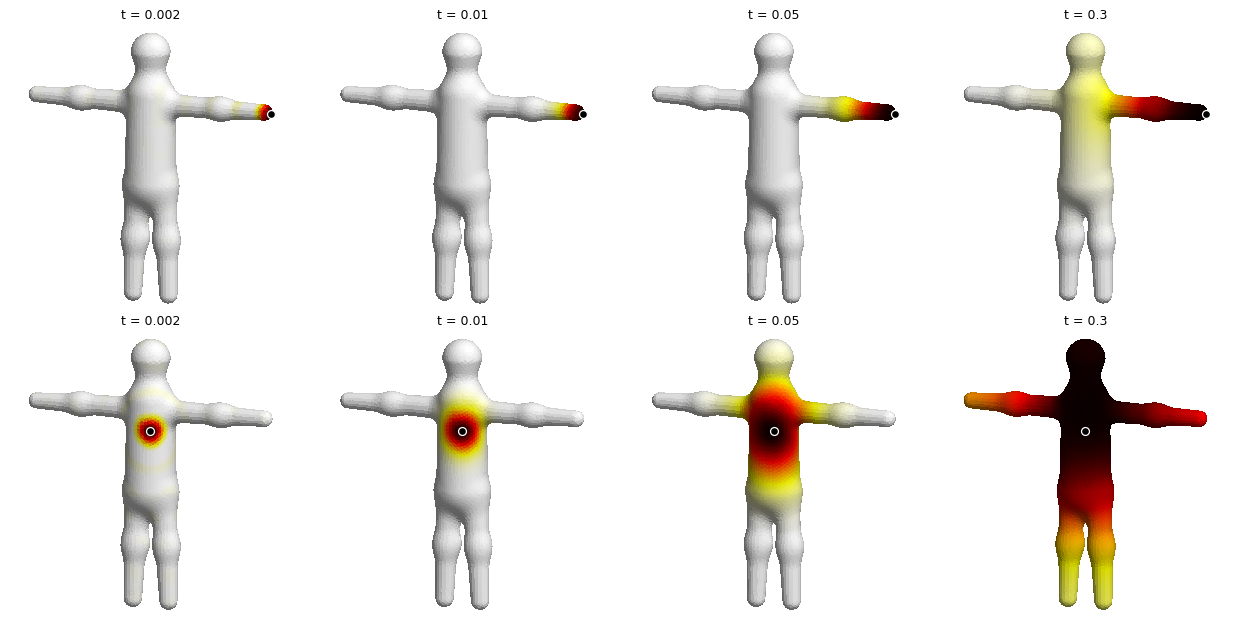

  t     K=20    K=50    K=100   K=200    (mín h / máx h)
 0.001 -0.166  -0.189  -0.209  -0.171
 0.005 -0.142  -0.125  -0.091  -0.016
 0.020 -0.066  -0.013  -0.001  -0.000


In [25]:
x_chest = int(np.argmin(np.linalg.norm(VA - np.array([0.1, 0.45, 0.25]), axis=1)))
fig, axs = plt.subplots(2, 4, figsize=(14, 7))
for r, x in enumerate([x_hand, x_chest]):
    for c, t in enumerate([0.002, 0.01, 0.05, 0.3]):
        render(axs[r, c], VA, FH, heat_kernel(lamA, PhiA, x, t), cmap='hot_r', view=VIEWS['humanoide'],
               mark=x, title=f't = {t}', vmin=0)
plt.tight_layout(); plt.show()

# Truncación: con pocos términos y t pequeño, el kernel tiene valores negativos (Gibbs)
print('  t     K=20    K=50    K=100   K=200    (mín h / máx h)')
for t in [0.001, 0.005, 0.02]:
    row = [heat_kernel(lamA[:K], PhiA[:, :K], x_hand, t) for K in [20, 50, 100, 200]]
    print(f'{t:6.3f}', '  '.join(f'{h.min()/h.max():+.3f}' for h in row))

La positividad sólo se cumple con **todos** los términos. Para $t$ pequeño necesitamos muchas
eigenfunciones (la regla práctica: $e^{-t\lambda_K}\ll1$); con pocas, el kernel oscila y
toma valores negativos. Por eso los descriptores de calor se evalúan en tiempos
$t\gtrsim 1/\lambda_K$.

---
# Bloque 4 — Mapas y distancias de difusión (25 min)

## 4.1 Kernels de difusión y la métrica que inducen

Generalizando el kernel de calor, un **kernel de difusión** es (slide 48)
$$g(x,x')=\sum_{k\ge1}G(\lambda_k)\,\phi_k(x)\,\phi_k(x'),\qquad G\ge0,\ \ \textstyle\sum_k G^2(\lambda_k)<\infty .$$
Define una distancia entre puntos comparando sus kernels como funciones:
$$d(x,x')=\|g(x,\cdot)-g(x',\cdot)\|_{L^2(\mathcal X)} .$$
Por **Parseval** (slide 50), esa integral se convierte en una distancia euclidiana entre
vectores de coeficientes:
$$d^2(x,x')=\sum_{k\ge1}G^2(\lambda_k)\,\big(\phi_k(x)-\phi_k(x')\big)^2=\|\Psi(x)-\Psi(x')\|^2,$$
con el **mapa de difusión** $\Psi:x\mapsto\{G(\lambda_k)\phi_k(x)\}_{k\ge1}$ (slide 49). El
término $k=1$ se cancela ($\phi_1$ es constante), así que empezamos en $k=2$.
Según $G$ obtenemos (slide 49):

| Nombre | $G(\lambda)$ |
|---|---|
| Eigenmap Laplaciano | $1$ (truncado a $m$ términos) |
| Mapa de difusión | $e^{-t\lambda}$ |
| *Global Point Signature* (GPS, Rustamov 2007) | $1/\sqrt\lambda$ |

### ✏️ Ejercicio 8 — Mapa espectral y distancia de difusión

1. `spectral_embedding(lam, Phi, G)` recibe una función `G` (que actúa sobre un arreglo de
   valores propios) y devuelve la matriz `(n, K-1)` con filas $\Psi(x)$, **omitiendo** $k=1$.
2. `distance_from(Psi, x)` devuelve el vector de distancias $\|\Psi(x)-\Psi(y)\|$ a todos los $y$.

El test verifica Parseval: la distancia calculada con el embedding debe coincidir con
$\|g(x,\cdot)-g(x',\cdot)\|_{\mathbf M}$ calculada en el dominio espacial.

In [26]:
# Ejercicio 8 — solución
def spectral_embedding(lam, Phi, G):
    return Phi[:, 1:] * G(lam[1:])

def distance_from(Psi, x):
    return np.linalg.norm(Psi - Psi[x], axis=1)

In [27]:
# Tests del Ejercicio 8
t = 0.05
Psi = spectral_embedding(lamA, PhiA, lambda l: np.exp(-t * l))
assert Psi.shape == (len(VA), KH - 1)
d_emb = distance_from(Psi, x_hand)
gx, gy = heat_kernel(lamA, PhiA, x_hand, t), heat_kernel(lamA, PhiA, x_foot, t)
d_int = np.sqrt((gx - gy) ** 2 @ MA.diagonal())
print(f'Parseval: embedding {d_emb[x_foot]:.6f} vs. integral {d_int:.6f}')
assert np.isclose(d_emb[x_foot], d_int, rtol=1e-6)
assert d_emb[x_hand] == 0
print('✅ Ejercicio 8 correcto')

Parseval: embedding 2.545512 vs. integral 2.545512
✅ Ejercicio 8 correcto


## 4.2 La escala $t$ y la comparación con la geodésica

Para cada kernel dibujamos la distancia desde la mano y medimos dos cosas sobre pares de
puntos: (i) cuánto cambia la distancia **entre poses** (comparado con la distancia euclidiana
en $\mathbb R^3$, que no es intrínseca) y (ii) su **correlación de rangos** (Spearman) con la
distancia geodésica.

kernel             | cambio entre poses (p90) | Spearman vs. geodésica
difusión t=0.005   |                   0.035 | 0.435
difusión t=0.05    |                   0.061 | 0.862
difusión t=0.5     |                   0.146 | 0.956
GPS 1/√λ           |                   0.035 | 0.938
euclidiana en R³   |                   0.241 |   —


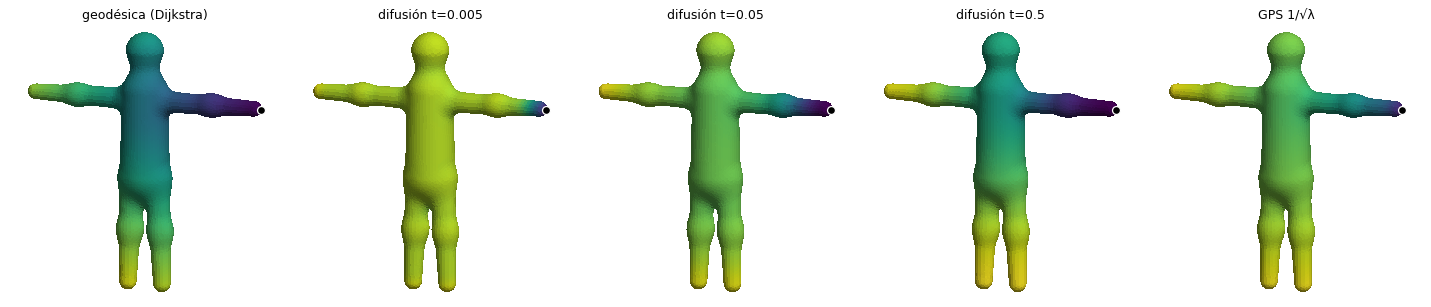

In [28]:
kernels = {'difusión t=0.005': lambda l: np.exp(-0.005 * l),
           'difusión t=0.05': lambda l: np.exp(-0.05 * l),
           'difusión t=0.5': lambda l: np.exp(-0.5 * l),
           'GPS 1/√λ': lambda l: 1 / np.sqrt(l)}
rng = np.random.default_rng(3); src = rng.choice(len(VA), 25, replace=False)
GEO_A = geodesics_from(VA, FH, src)
fig, axs = plt.subplots(1, 5, figsize=(16, 4))
render(axs[0], VA, FH, geodesics_from(VA, FH, x_hand)[0], cmap='viridis', view=VIEWS['humanoide'],
       mark=x_hand, title='geodésica (Dijkstra)')
print(f'{"kernel":18s} | cambio entre poses (p90) | Spearman vs. geodésica')
for ax, (name, G) in zip(axs[1:], kernels.items()):
    PsiA, PsiB = spectral_embedding(lamA, PhiA, G), spectral_embedding(lamB, PhiB, G)
    render(ax, VA, FH, distance_from(PsiA, x_hand), cmap='viridis', view=VIEWS['humanoide'], mark=x_hand, title=name)
    ch, rho = [], []
    for i, x in enumerate(src):
        dA, dB = distance_from(PsiA, x), distance_from(PsiB, x)
        m = dA > 1e-3 * dA.max()
        ch.append(np.abs(dB[m] / dA[m] - 1)); rho.append(spearmanr(dA, GEO_A[i])[0])
    print(f'{name:18s} | {np.percentile(np.concatenate(ch), 90):23.3f} | {np.median(rho):.3f}')
ch = []
for x in src:
    eA, eB = np.linalg.norm(VA - VA[x], axis=1), np.linalg.norm(VB - VB[x], axis=1); m = eA > 0.05
    ch.append(np.abs(eB[m] / eA[m] - 1))
print(f'{"euclidiana en R³":18s} | {np.percentile(np.concatenate(ch), 90):23.3f} |   —')
plt.tight_layout(); plt.show()

* Las distancias de difusión cambian bastante menos entre poses que la euclidiana (que depende
  de si la mano se acerca o se aleja del pie). El cambio crece con $t$: a escala grande pesan
  las primeras eigenfunciones, y la pose B dobla una rodilla, lo que mueve algo $\lambda_4$.
* Con $t$ **pequeño** el kernel de cada punto está muy concentrado: dos puntos lejanos tienen
  kernels disjuntos y su distancia **satura** en $\sqrt{h_t(x,x)+h_t(y,y)}$. Por eso la
  correlación con la geodésica es baja: la distancia de difusión sólo distingue lo cercano.
* Con $t$ **grande** sólo sobreviven las primeras frecuencias: la distancia refleja la
  estructura gruesa (qué extremidad), parecido a una geodésica "suavizada". Distintas escalas
  ven distintas cosas (slide 51).

## 4.3 Forma canónica: el embedding GPS

Las tres primeras coordenadas del mapa GPS, $\big(\phi_2/\sqrt{\lambda_2},\phi_3/\sqrt{\lambda_3},\phi_4/\sqrt{\lambda_4}\big)$,
son un embedding de la superficie en $\mathbb R^3$ que **no depende de la pose**, salvo el
signo de cada eje (que corregimos con `sign_fix` del Ejercicio 4). Coloreamos los puntos por la
coordenada $y$ de la pose A para seguir las partes.

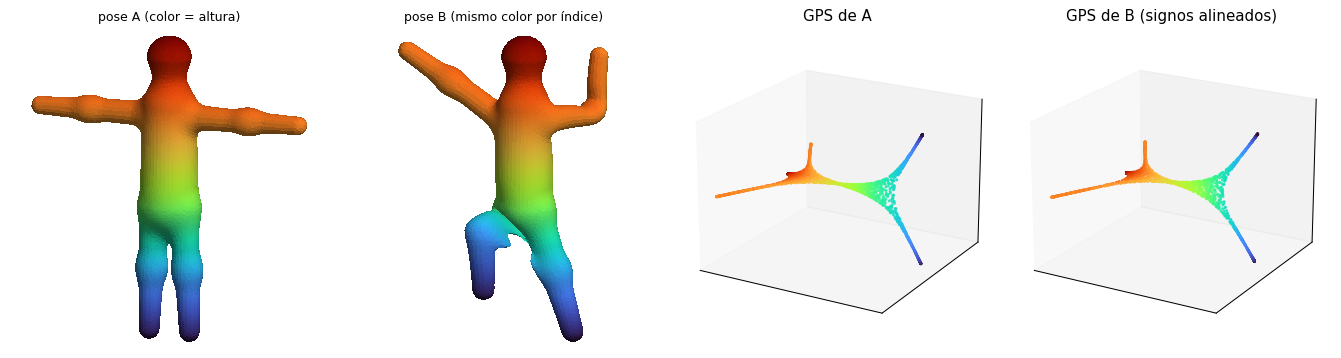

‖E_A − E_B‖ / ‖E_A‖ = 0.0736


In [29]:
GPS = lambda l: 1 / np.sqrt(l)
EA = spectral_embedding(lamA, PhiA, GPS)[:, :3]
EB = spectral_embedding(lamB, PhiB, GPS)[:, :3] * s_AB[1:4]
fig = plt.figure(figsize=(15, 4.5))
render(fig.add_subplot(1, 4, 1), VA, FH, VA[:, 1], cmap='turbo', view=VIEWS['humanoide'], title='pose A (color = altura)')
render(fig.add_subplot(1, 4, 2), VB, FH, VA[:, 1], cmap='turbo', view=VIEWS['humanoide'], title='pose B (mismo color por índice)')
for j, (E, ttl) in enumerate([(EA, 'GPS de A'), (EB, 'GPS de B (signos alineados)')]):
    ax = fig.add_subplot(1, 4, 3 + j, projection='3d')
    ax.scatter(E[::3, 0], E[::3, 1], E[::3, 2], c=VA[::3, 1], cmap='turbo', s=2)
    ax.set_title(ttl); ax.view_init(20, -60); ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
plt.tight_layout(); plt.show()
print('‖E_A − E_B‖ / ‖E_A‖ =', round(np.linalg.norm(EA - EB) / np.linalg.norm(EA), 4))

Las dos poses colapsan en prácticamente la misma "forma canónica": el embedding elimina la
pose y deja la estructura intrínseca (brazos, piernas y cabeza como ramas de un árbol).
Compararlo con el espacio original es la idea de las *formas canónicas* de Elad y Kimmel
(2003), con distancias de difusión en lugar de geodésicas.

---
# Bloque 5 — Descriptores locales: HKS y WKS (40 min)

## 5.1 Heat Kernel Signature (Sun, Ovsjanikov y Guibas, 2009)

La **autodifusividad** $h_t(x,x)$ es cuánto calor **permanece** en $x$ después de un tiempo
$t$ si partimos con calor concentrado en $x$ (slide 52):
$$\mathrm{HKS}(x,t)=h_t(x,x)=\sum_{k\ge1}e^{-\lambda_kt}\,\phi_k^2(x).$$
Muestreando $t_1<\dots<t_Q$ cada punto recibe un vector $\big(h_{t_1}(x,x),\dots,h_{t_Q}(x,x)\big)$.
Es intrínseco, denso, multiescala y barato de calcular (slide 53). Observa que depende de
$\phi_k^2$: **el signo de las eigenfunciones ya no importa**, y en un espacio propio múltiple
$\sum\phi_k^2$ tampoco depende de la base elegida.

Elección estándar de tiempos (Sun et al.): $Q$ valores log-espaciados entre
$t_{\min}=4\ln10/\lambda_K$ y $t_{\max}=4\ln10/\lambda_2$. Con $t<t_{\min}$ faltarían
eigenfunciones (ver Bloque 3); con $t>t_{\max}$ todos los puntos tienden a $1/A$.

Para que distintas formas sean comparables se suele normalizar cada columna por la
**traza de calor** $Z(t)=\int_{\mathcal X} h_t(x,x)\,dx=\sum_k e^{-\lambda_kt}$ (*scaled HKS*).

### ✏️ Ejercicio 9 — Heat Kernel Signature

1. `hks_times(lam, Q=16)` devuelve los $Q$ tiempos log-espaciados entre $4\ln10/\lambda_K$ y
   $4\ln10/\lambda_2$ (aquí $\lambda_K$ es el mayor valor propio disponible).
2. `hks(lam, Phi, ts)` devuelve la matriz `(n, Q)` de $h_t(x,x)$, vectorizada.
3. `scaled_hks(lam, Phi, M, ts)` divide cada columna por su integral $\mathbf 1^\top\mathbf M\,\mathrm{HKS}(\cdot,t)$.

In [30]:
# Ejercicio 9 — solución
def hks_times(lam, Q=16):
    return np.geomspace(4 * np.log(10) / lam[-1], 4 * np.log(10) / lam[1], Q)

def hks(lam, Phi, ts):
    return (Phi ** 2) @ np.exp(-np.outer(lam, ts))

def scaled_hks(lam, Phi, M, ts):
    H = hks(lam, Phi, ts)
    return H / (M.diagonal() @ H)

In [31]:
# Tests del Ejercicio 9
TS = hks_times(lamA)
assert TS.shape == (16,) and np.isclose(TS[0], 4 * np.log(10) / lamA[-1]) and np.isclose(TS[-1], 4 * np.log(10) / lamA[1])
HA, HB = hks(lamA, PhiA, TS), hks(lamB, PhiB, TS)
assert HA.shape == (len(VA), 16)
assert np.allclose(MA.diagonal() @ HA, np.exp(-np.outer(lamA, TS)).sum(0)), '∫ HKS = traza de calor'
sHA = scaled_hks(lamA, PhiA, MA, TS)
assert np.allclose(MA.diagonal() @ sHA, 1)
Hs = hks(lam_s, Phi_s, [0.1])[:, 0]                         # esfera del Ejercicio 1
print(f'esfera: desviación relativa de HKS entre vértices = {Hs.std()/Hs.mean():.1e}')
assert Hs.std() / Hs.mean() < 0.02, 'en la esfera todos los puntos son equivalentes'
rel = np.median(np.abs(HB / HA - 1), axis=0)
print('cambio relativo mediano entre poses, por tiempo:', rel.round(3))
assert np.all(rel < 0.05)
print('✅ Ejercicio 9 correcto')

esfera: desviación relativa de HKS entre vértices = 7.3e-04
cambio relativo mediano entre poses, por tiempo: [0.008 0.012 0.016 0.021 0.022 0.021 0.015 0.012 0.009 0.007 0.007 0.006 0.003 0.003 0.003 0.003]
✅ Ejercicio 9 correcto


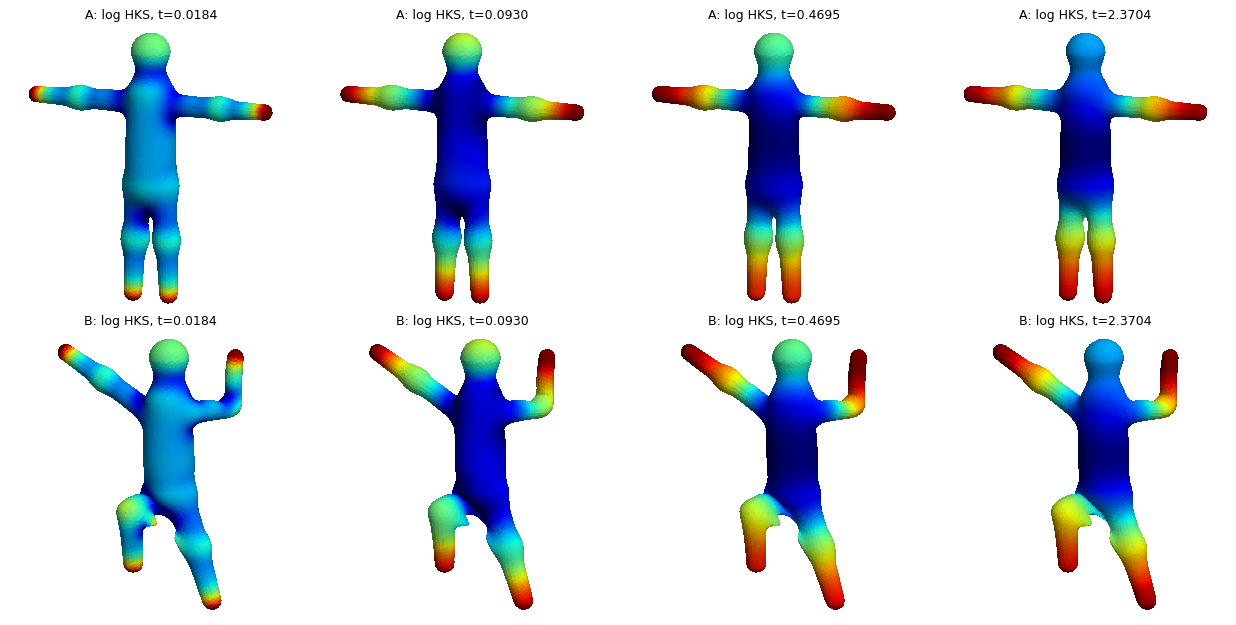

In [32]:
fig, axs = plt.subplots(2, 4, figsize=(14, 7))
for c, q in enumerate([0, 4, 8, 12]):
    lo, hi = np.percentile(np.log(np.r_[HA[:, q], HB[:, q]]), [1, 99])
    render(axs[0, c], VA, FH, np.log(HA[:, q]), cmap='jet', vmin=lo, vmax=hi, view=VIEWS['humanoide'], title=f'A: log HKS, t={TS[q]:.4f}')
    render(axs[1, c], VB, FH, np.log(HB[:, q]), cmap='jet', vmin=lo, vmax=hi, view=VIEWS['humanoide'], title=f'B: log HKS, t={TS[q]:.4f}')
plt.tight_layout(); plt.show()

Igual que en la slide 54: a tiempo **pequeño** la HKS resalta detalles finos (puntas de
manos, pies, nariz… aquí las zonas más curvas); a tiempo **grande** destaca extremidades
enteras, donde el calor queda "atrapado" porque tiene poca superficie por donde escapar.

## 5.2 HKS y curvatura de Gauss

Para $t\to0$ (slide 55):
$$h_t(x,x)\approx\frac{1}{4\pi t}+\frac{K(x)}{12\pi}+\mathcal O(t).$$
El primer término es el del plano, igual para todos los puntos; el segundo dice que el calor
se queda más donde la curvatura de Gauss $K$ es positiva. Lo verificamos en un elipsoide,
donde $K$ se conoce analíticamente:
$$K=\frac{1}{a^2b^2c^2\big(\tfrac{x^2}{a^4}+\tfrac{y^2}{b^4}+\tfrac{z^2}{c^4}\big)^2}.$$
Primero necesitamos la curvatura **discreta**: el **defecto angular**
$K_i=\big(2\pi-\sum_{j}\theta_{ij}\big)/A_i$, donde $\theta_{ij}$ son los ángulos de los
triángulos en el vértice $i$ y $A_i$ su área de Voronoi/baricéntrica (la diagonal de $\mathbf M$).

### ✏️ Ejercicio 10 — Curvatura de Gauss por defecto angular

Implementa `angle_defect_curvature(V, F)` (vectorizado: calcula los tres ángulos de cada
triángulo y acumúlalos por vértice con `np.bincount`). Divide por la masa baricéntrica.

El test verifica el **teorema de Gauss–Bonnet discreto**, que se cumple de forma **exacta**:
$\sum_i K_iA_i=2\pi\chi$.

In [33]:
# Ejercicio 10 — solución
def angle_defect_curvature(V, F):
    A = mass_matrix(V, F).diagonal()
    angle_sum = np.zeros(len(V))
    for i in range(3):
        a, b, c = F[:, i], F[:, (i + 1) % 3], F[:, (i + 2) % 3]
        u, v = V[b] - V[a], V[c] - V[a]
        cosang = (u * v).sum(1) / (np.linalg.norm(u, axis=1) * np.linalg.norm(v, axis=1))
        angle_sum += np.bincount(a, np.arccos(np.clip(cosang, -1, 1)), minlength=len(V))
    return (2 * np.pi - angle_sum) / A

In [34]:
# Tests del Ejercicio 10
abc = np.array([1.3, 1.0, 0.6])
V_e3, F_e3 = icosphere(3); V_e3 = V_e3 * abc
V_e4, F_e4 = icosphere(4); V_e4 = V_e4 * abc
def K_ellipsoid(V):
    x, y, z = V.T; a, b, c = abc
    return 1 / (a * b * c) ** 2 / ((x / a**2) ** 2 + (y / b**2) ** 2 + (z / c**2) ** 2) ** 2
for nm, (V_, F_) in {'elipsoide': (V_e4, F_e4), 'toro': torus(), 'humanoide': (VA, FH),
                      'cuadrúpedo': (DATA['cuadrupedo']['poses'][2], DATA['cuadrupedo']['F'])}.items():
    Kd = angle_defect_curvature(V_, F_)
    gb = Kd @ mass_matrix(V_, F_).diagonal()
    print(f'{nm:10s}: Σ K_i A_i = {gb:+.10f}   2πχ = {2*np.pi*euler_characteristic(V_, F_):+.10f}')
    assert np.isclose(gb, 2 * np.pi * euler_characteristic(V_, F_), atol=1e-8)
Kd_e4 = angle_defect_curvature(V_e4, F_e4)
r = pearsonr(Kd_e4, K_ellipsoid(V_e4))[0]
print(f'correlación defecto angular vs. K analítica en el elipsoide: {r:.4f}')
assert r > 0.99
print('✅ Ejercicio 10 correcto')

elipsoide : Σ K_i A_i = +12.5663706144   2πχ = +12.5663706144
toro      : Σ K_i A_i = -0.0000000000   2πχ = +0.0000000000
humanoide : Σ K_i A_i = +12.5663706144   2πχ = +12.5663706144
cuadrúpedo: Σ K_i A_i = +12.5663706144   2πχ = +12.5663706144
correlación defecto angular vs. K analítica en el elipsoide: 0.9999
✅ Ejercicio 10 correcto


Ahora la relación HKS–curvatura. Para $t$ pequeño necesitamos **todo** el espectro, así que
usamos el elipsoide con 642 y 2562 vértices y `scipy.linalg.eigh` denso (≈ 5 s).
Graficamos la correlación entre $\mathrm{HKS}(x,t)$ y $K(x)$ en función de $t$, relativo al
tamaño de arista $h$.

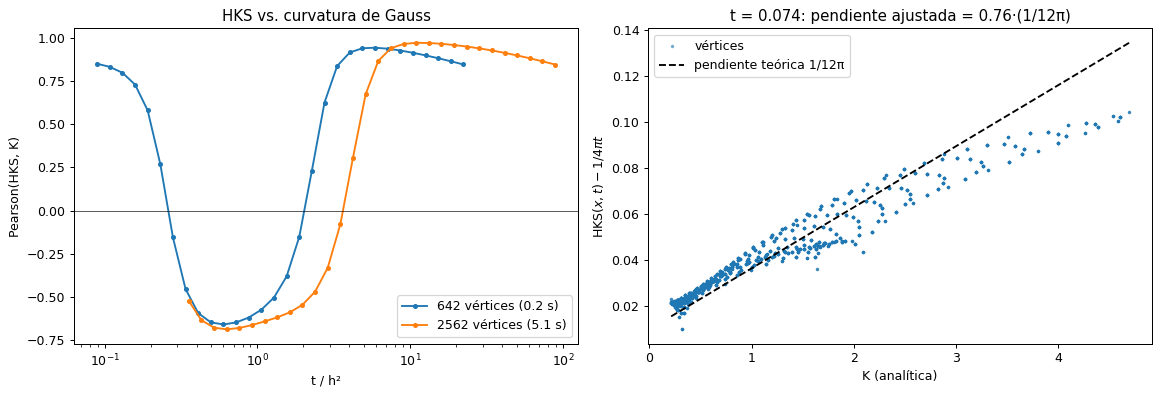

In [35]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
tgrid = np.geomspace(2e-3, 0.5, 30)
for (V_, F_), lbl in [((V_e3, F_e3), '642 vértices'), ((V_e4, F_e4), '2562 vértices')]:
    t0 = time.time()
    lam_d, Phi_d = sl.eigh(cotan_laplacian(V_, F_).toarray(), mass_matrix(V_, F_).toarray())
    h = np.linalg.norm(V_[F_[:, 0]] - V_[F_[:, 1]], axis=1).mean()
    K_ = K_ellipsoid(V_)
    H_ = hks(lam_d, Phi_d, tgrid)
    corr = [pearsonr(H_[:, j], K_)[0] for j in range(len(tgrid))]
    axs[0].semilogx(tgrid / h**2, corr, 'o-', ms=3, label=f'{lbl} ({time.time()-t0:.1f} s)')
    if lbl.startswith('2562'):
        j = np.argmin(np.abs(tgrid - 0.08)); Hj = H_[:, j]
        axs[1].scatter(K_, Hj - 1 / (4 * np.pi * tgrid[j]), s=3, alpha=.5, label='vértices')
        kk = np.linspace(K_.min(), K_.max(), 2)
        b = np.mean(Hj - 1 / (4 * np.pi * tgrid[j]) - K_ / (12 * np.pi))
        axs[1].plot(kk, kk / (12 * np.pi) + b, 'k--', label='pendiente teórica 1/12π')
        slope = np.polyfit(K_, Hj, 1)[0]
        axs[1].set(xlabel='K (analítica)', ylabel=r'HKS$(x,t) - 1/4\pi t$',
                   title=f't = {tgrid[j]:.3f}: pendiente ajustada = {slope*12*np.pi:.2f}·(1/12π)')
        axs[1].legend()
axs[0].axhline(0, color='k', lw=.5); axs[0].set(xlabel='t / h²', ylabel='Pearson(HKS, K)', title='HKS vs. curvatura de Gauss')
axs[0].legend(); plt.tight_layout(); plt.show()

Hay una **ventana** de tiempos útil: si $t$ es del orden de $h^2$ (pocas aristas de radio), la
HKS refleja la **discretización** (la irregularidad de la malla) y la correlación con $K$
llega a ser negativa; con $t$ grande la expansión asintótica deja de valer, porque los
términos $\mathcal O(t)$ pesan. Al refinar la malla la ventana se abre hacia $t$ más
pequeños. La pendiente ajustada queda cerca de la teórica, pero no igual, por esos términos
de orden superior.

## 5.3 Wave Kernel Signature (Aubry, Schlickewei y Cremers, 2011)

La HKS es un filtro **pasa-bajos**: incluso en el $t$ más pequeño suma todas las frecuencias bajas,
así que los descriptores de puntos vecinos se parecen mucho y la localización es pobre. La
**WKS** cambia el modelo físico: una partícula cuántica con distribución de energía inicial
$f_e(\lambda)$ que evoluciona según la ecuación de Schrödinger (slides 56–57). Promediando en
el tiempo, la probabilidad de encontrarla en $x$ es
$$\mathrm{WKS}(x,e)=\sum_{k\ge2}f_e^2(\lambda_k)\,\phi_k^2(x)\Big/\sum_{k\ge2}f_e^2(\lambda_k),
\qquad f_e^2(\lambda)=\exp\!\Big(-\frac{(e-\log\lambda)^2}{2\sigma^2}\Big).$$
Cada energía $e$ selecciona una **banda** de frecuencias en escala logarítmica: es un filtro
**pasa-banda**. Parámetros habituales: $E$ energías equiespaciadas entre $\log\lambda_2$ y
$\log\lambda_K$, y $\sigma=7\,\delta e$.

### ✏️ Ejercicio 11 — Wave Kernel Signature

Implementa `wks(lam, Phi, E=100, wmult=7)`:

* usa sólo $k\ge2$ (descarta $\lambda_1=0$, cuyo logaritmo no existe);
* energías `e = np.linspace(log λ_2, log λ_K / 1.02, E)` (el factor 1.02 evita centrar la
  última banda justo en el borde del espectro disponible);
* $\sigma$ = `wmult * (e[1] - e[0])`;
* devuelve la matriz `(n, E)` normalizada por $\sum_k f_e^2(\lambda_k)$.

Como $\int\phi_k^2=1$, cada columna de la WKS integra exactamente 1: es una distribución de
probabilidad sobre la superficie.

In [36]:
# Ejercicio 11 — solución
def wks(lam, Phi, E=100, wmult=7):
    loglam = np.log(lam[1:]); P2 = Phi[:, 1:] ** 2
    e = np.linspace(loglam[0], loglam[-1] / 1.02, E)
    sigma = wmult * (e[1] - e[0])
    W = np.exp(-(e[None, :] - loglam[:, None]) ** 2 / (2 * sigma ** 2))     # (K-1, E)
    return (P2 @ W) / W.sum(0)

In [37]:
# Tests del Ejercicio 11
WA, WB = wks(lamA, PhiA), wks(lamB, PhiB)
assert WA.shape == (len(VA), 100)
assert np.allclose(MA.diagonal() @ WA, 1), 'cada columna integra 1'
rel = np.median(np.abs(WB / WA - 1), axis=0)
print(f'cambio relativo mediano entre poses: energías bajas {rel[:50].mean():.3f}, energías altas {rel[50:].mean():.3f}')
assert np.median(rel) < 0.1 and np.all(rel < 0.25)
print('✅ Ejercicio 11 correcto')

cambio relativo mediano entre poses: energías bajas 0.085, energías altas 0.024
✅ Ejercicio 11 correcto


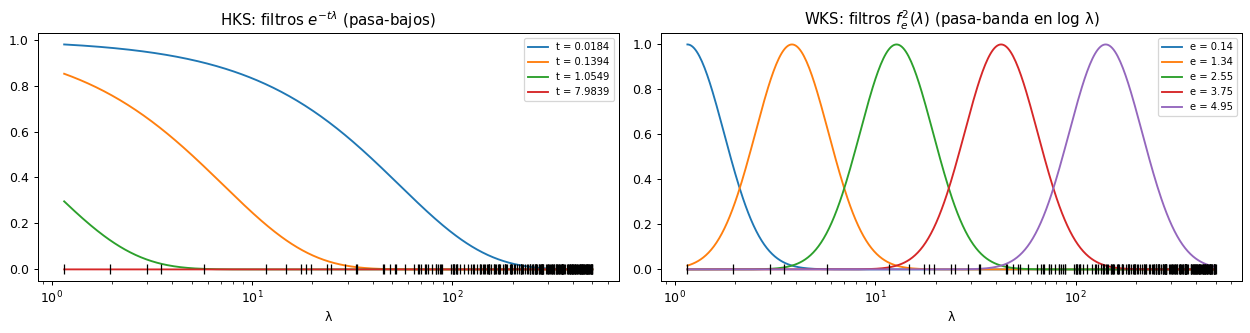

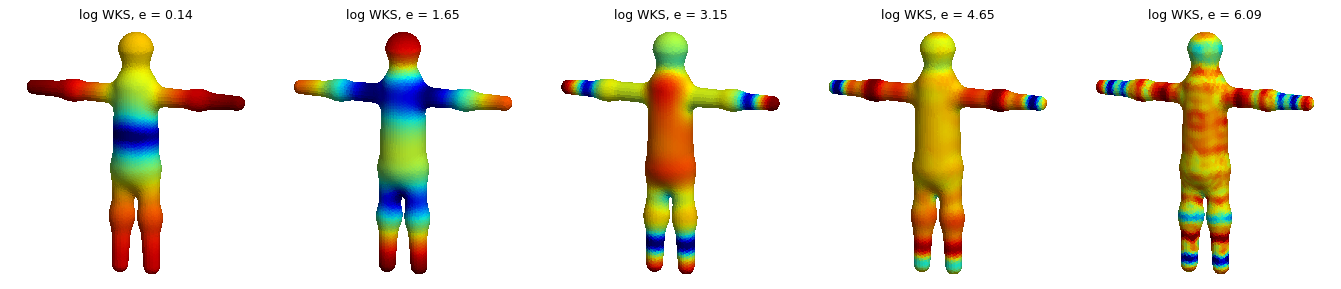

In [38]:
fig, axs = plt.subplots(1, 2, figsize=(14, 3.8))
lgrid = np.geomspace(lamA[1], lamA[-1], 400)
for t in TS[::5]:
    axs[0].semilogx(lgrid, np.exp(-t * lgrid), label=f't = {t:.4f}')
axs[0].set(title='HKS: filtros $e^{-t\\lambda}$ (pasa-bajos)', xlabel='λ'); axs[0].legend(fontsize=8)
e = np.linspace(np.log(lamA[1]), np.log(lamA[-1]) / 1.02, 100); sig = 7 * (e[1] - e[0])
for ej in e[::20]:
    axs[1].semilogx(lgrid, np.exp(-(ej - np.log(lgrid)) ** 2 / (2 * sig ** 2)), label=f'e = {ej:.2f}')
axs[1].set(title='WKS: filtros $f_e^2(\\lambda)$ (pasa-banda en log λ)', xlabel='λ'); axs[1].legend(fontsize=8)
for ax in axs:
    ax.plot(lamA[1:], np.zeros(KH - 1), '|k', ms=8)
plt.tight_layout(); plt.show()

fig, axs = plt.subplots(1, 5, figsize=(15, 3.6))
for ax, q in zip(axs, [0, 25, 50, 75, 99]):
    w = np.log(WA[:, q]); lo, hi = np.percentile(w, [1, 99])
    render(ax, VA, FH, w, cmap='jet', vmin=lo, vmax=hi, view=VIEWS['humanoide'], title=f'log WKS, e = {e[q]:.2f}')
plt.tight_layout(); plt.show()

Energías bajas resaltan partes grandes; energías altas, detalles finos. A diferencia de la HKS,
una energía alta **no** incluye las frecuencias bajas, y eso hace a la WKS más discriminativa.

## 5.4 Correspondencias por descriptores

La prueba final: para cada punto de la pose A buscamos el punto de la pose B con el descriptor
más parecido (vecino más cercano en el espacio de descriptores) y medimos el **error
geodésico** respecto del punto correcto, normalizado por $\sqrt{A}$. Es el protocolo de Kim,
Lipman y Funkhouser (2011): curva del porcentaje de correspondencias con error menor que $r$.

### ✏️ Ejercicio 12 — Correspondencias por vecino más cercano

Implementa `match_descriptors(DA, DB, idx)`: para cada vértice `idx[i]` de A devuelve el índice
del vértice de B cuyo descriptor está más cerca en norma euclidiana, comparando
**logaritmos** de los descriptores (ambos son positivos y varían en órdenes de magnitud).
Usa `cKDTree`.

In [39]:
# Ejercicio 12 — solución
def match_descriptors(DA, DB, idx):
    tree = cKDTree(np.log(DB))
    _, nn = tree.query(np.log(DA[idx]))
    return nn

In [40]:
# Tests del Ejercicio 12
idx_test = np.arange(0, len(VA), 50)
assert np.array_equal(match_descriptors(WA, WA, idx_test), idx_test), 'A consigo misma: identidad'
nn = match_descriptors(WA, WB, idx_test)
assert nn.shape == idx_test.shape
print(f'coincidencias exactas WKS A→B: {np.mean(nn == idx_test):.1%} (de {len(idx_test)})')
print('✅ Ejercicio 12 correcto')

coincidencias exactas WKS A→B: 5.4% (de 111)
✅ Ejercicio 12 correcto


Evaluamos en el humanoide (A → B) y en el cuadrúpedo (pose 0 → pose 1). Ambos tienen
simetría izquierda–derecha, así que medimos además el error **módulo simetría**: el mínimo
entre la distancia al punto correcto y a su reflejo.

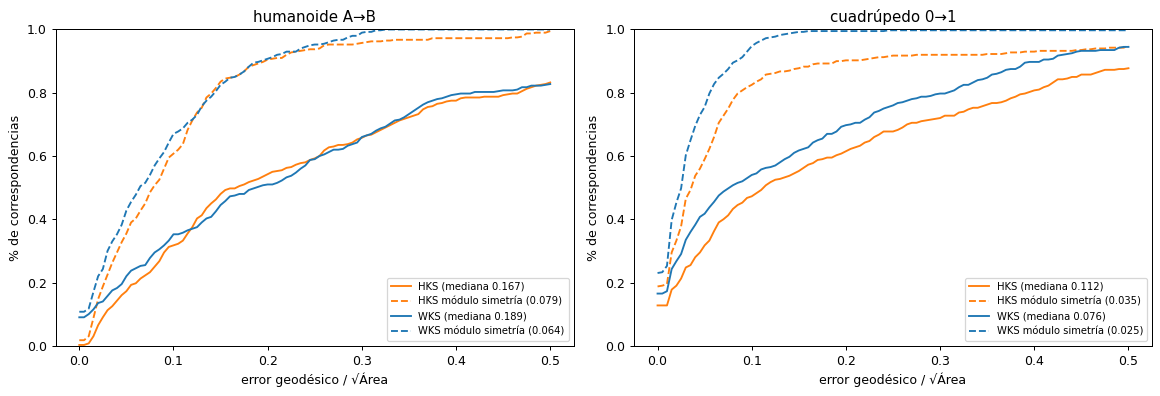

In [41]:
def symmetry_map(V, axis):
    Vm = V.copy(); Vm[:, axis] *= -1
    return cKDTree(V).query(Vm)[1]

cases = {}
dQ = DATA['cuadrupedo']
lamQ0, PhiQ0, _, MQ0 = laplace_spectrum(dQ['poses'][0], dQ['F'], KH)
lamQ1, PhiQ1, _, MQ1 = laplace_spectrum(dQ['poses'][1], dQ['F'], KH)
cases['humanoide A→B'] = (VA, VB, FH, (lamA, PhiA, MA), (lamB, PhiB, MB), symmetry_map(VA, 0))
cases['cuadrúpedo 0→1'] = (dQ['poses'][0], dQ['poses'][1], dQ['F'], (lamQ0, PhiQ0, MQ0), (lamQ1, PhiQ1, MQ1),
                           symmetry_map(dQ['poses'][0], 2))
r_grid = np.linspace(0, 0.5, 101)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
rng = np.random.default_rng(7)
for ax, (name, (V0_, V1_, F_, sA, sB, sym)) in zip(axs, cases.items()):
    idx = rng.choice(len(V0_), 400, replace=False)
    G1 = geodesics_from(V1_, F_, idx); G1s = geodesics_from(V1_, F_, sym[idx])
    sqA = np.sqrt(sA[2].diagonal().sum())
    ts_ = hks_times(sA[0])
    descs = {'HKS': (scaled_hks(*sA, ts_), scaled_hks(*sB, ts_)), 'WKS': (wks(*sA[:2]), wks(*sB[:2]))}
    for (dname, (DA_, DB_)), col in zip(descs.items(), ['tab:orange', 'tab:blue']):
        nn = match_descriptors(DA_, DB_, idx)
        err = G1[np.arange(len(idx)), nn] / sqA
        err_s = np.minimum(err, G1s[np.arange(len(idx)), nn] / sqA)
        ax.plot(r_grid, [(err <= r).mean() for r in r_grid], color=col, label=f'{dname} (mediana {np.median(err):.3f})')
        ax.plot(r_grid, [(err_s <= r).mean() for r in r_grid], '--', color=col, label=f'{dname} módulo simetría ({np.median(err_s):.3f})')
    ax.set(xlabel='error geodésico / √Área', ylabel='% de correspondencias', title=name, ylim=(0, 1)); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

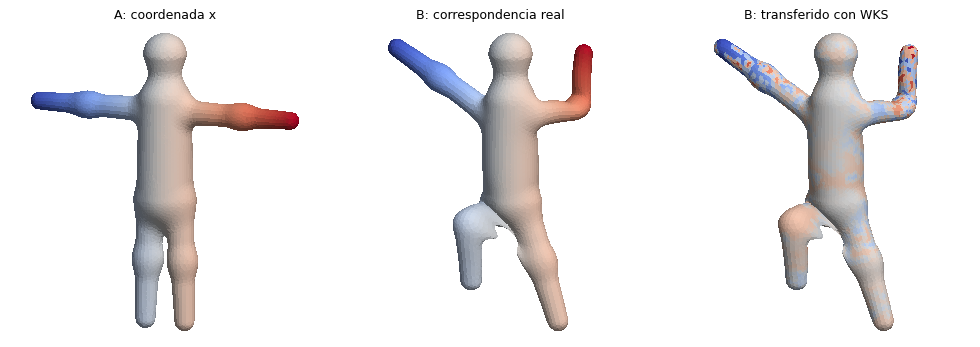

In [42]:
# ¿Dónde se equivoca? Para cada vértice de B buscamos su par en A (WKS) y le pintamos
# la coordenada x de A (izquierda = azul, derecha = rojo). Un mapa perfecto pintaría B igual que A.
nnB = match_descriptors(WB, WA, np.arange(len(VB)))
fig, axs = plt.subplots(1, 3, figsize=(11, 4.2))
render(axs[0], VA, FH, VA[:, 0], cmap='coolwarm', view=VIEWS['humanoide'], title='A: coordenada x')
render(axs[1], VB, FH, VA[:, 0], cmap='coolwarm', view=VIEWS['humanoide'], title='B: correspondencia real')
render(axs[2], VB, FH, VA[nnB, 0], cmap='coolwarm', view=VIEWS['humanoide'], title='B: transferido con WKS')
plt.tight_layout(); plt.show()

Lo que muestran las curvas:

* En el cuadrúpedo la **WKS** localiza mejor que la **HKS**, como se espera de un filtro
  pasa-banda. En el humanoide, sin descontar la simetría, quedan parejas: el error está dominado
  por puntos asignados al lado equivocado, y ahí ninguna de las dos ayuda.
* Una parte importante del error es una **simetría intrínseca**: el brazo izquierdo y el derecho
  son (casi) isométricos entre sí, así que **ningún** descriptor intrínseco puntual puede
  distinguirlos. En la transferencia de color se ven parches con el lado intercambiado. Módulo
  simetría, el error mediano baja a la mitad o menos.
* El vecino más cercano punto a punto ignora la **coherencia espacial** (puntos vecinos deberían
  ir a puntos vecinos). Los métodos modernos combinan estos descriptores con esa
  restricción: **mapas funcionales** (la matriz $\mathbf C$ del Ejercicio 4, estimada a partir de
  descriptores) y sus refinamientos (ZoomOut, etc.).

---
# Bloque 6 — Cierre (5 min)

| Herramienta | Qué usa del espectro | Invariante a | Sensible a |
|---|---|---|---|
| ShapeDNA | $\{A\lambda_k\}$ | isometrías, escala, triangulación | topología; no distingue isoespectrales |
| Eigenfunciones | $\phi_k$ | isometrías (salvo signo, cruces, multiplicidad) | elección de base en espacios propios |
| Kernel de calor | $e^{-t\lambda_k}\phi_k(x)\phi_k(y)$ | isometrías; independiente de la base | truncación para $t$ pequeño |
| Distancia de difusión / GPS | $G(\lambda_k)\phi_k(x)$ | isometrías | signo (en el embedding, no en la distancia) |
| HKS | $\sum e^{-t\lambda_k}\phi_k^2(x)$ | isometrías; independiente de la base | escala global; localización pobre |
| WKS | $\sum f_e^2(\lambda_k)\phi_k^2(x)$ | isometrías; independiente de la base | ruido de alta frecuencia |

### Preguntas para discutir

1. ¿Por qué resolvemos $\mathbf L\phi=\lambda\mathbf M\phi$ y no $\mathbf M^{-1}\mathbf L\phi=\lambda\phi$ con un solver no simétrico? ¿Qué se pierde si se usa el Laplaciano uniforme (de grafo)?
2. La ShapeDNA del humanoide con la mano tocando la cadera cambió mucho. Propón un preprocesamiento o una modificación del descriptor para ser robusto a ese tipo de contacto.
3. ¿Por qué la HKS y la WKS no sufren el problema de signo de las eigenfunciones, mientras que el embedding GPS sí?
4. Si escalamos una forma por $s$, ¿cómo cambia $\mathrm{HKS}(x,t)$? ¿Cómo construirías una HKS invariante a escala? (Bronstein y Kokkinos, 2010).
5. En la Figura de HKS vs. curvatura, ¿por qué la correlación es negativa para $t\sim h^2$? ¿Qué pasaría con una malla perfectamente regular?
6. La distancia de difusión con $t$ pequeño satura. ¿Qué kernel $G$ elegirías para aproximar la distancia geodésica? (Pista: la fórmula de Varadhan, $d^2(x,y)=\lim_{t\to0}-4t\log h_t(x,y)$, y el *heat method*).
7. Los errores de correspondencia "módulo simetría" son mucho menores. ¿Qué información **extrínseca** o **global** usarías para romper la simetría izquierda/derecha?

### Bibliografía

* M. Reuter, F.-E. Wolter, N. Peinecke. *Laplace–Beltrami spectra as "Shape-DNA" of surfaces and solids.* CAD, 2006.
* B. Lévy. *Laplace–Beltrami eigenfunctions: towards an algorithm that "understands" geometry.* SMI, 2006.
* B. Vallet, B. Lévy. *Spectral geometry processing with manifold harmonics.* CGF (Eurographics), 2008.
* M. Wardetzky, S. Mathur, F. Kälberer, E. Grinspun. *Discrete Laplace operators: no free lunch.* SGP, 2007.
* R. Coifman, S. Lafon. *Diffusion maps.* Applied and Computational Harmonic Analysis, 2006.
* R. Rustamov. *Laplace–Beltrami eigenfunctions for deformation invariant shape representation.* SGP, 2007.
* J. Sun, M. Ovsjanikov, L. Guibas. *A concise and provably informative multi-scale signature based on heat diffusion.* SGP, 2009.
* M. Bronstein, I. Kokkinos. *Scale-invariant heat kernel signatures for non-rigid shape recognition.* CVPR, 2010.
* M. Aubry, U. Schlickewei, D. Cremers. *The wave kernel signature: a quantum mechanical approach to shape analysis.* ICCV Workshops, 2011.
* V. Kim, Y. Lipman, T. Funkhouser. *Blended intrinsic maps.* SIGGRAPH, 2011.
* M. Ovsjanikov, M. Ben-Chen, J. Solomon, A. Butscher, L. Guibas. *Functional maps: a flexible representation of maps between shapes.* SIGGRAPH, 2012.
* C. Gordon, D. Webb, S. Wolpert. *One cannot hear the shape of a drum.* Bulletin of the AMS, 1992.

---
# ★ Opcional (para casa): el conejo de Stanford

Las slides 42–47 muestran difusión de calor y el kernel de calor sobre el conejo. Esta celda
descarga la malla (≈ 35 000 vértices) del repositorio `alecjacobson/common-3d-test-models`
y repite los experimentos. Necesita internet y tarda alrededor de un minuto. El conejo tiene
agujeros en la base: el Laplaciano de cotangentes impone ahí, de forma natural, condiciones
de **Neumann** (el calor no se escapa por el borde).

conejo: 34834 vértices, 69451 caras
eigsh: 10.2 s


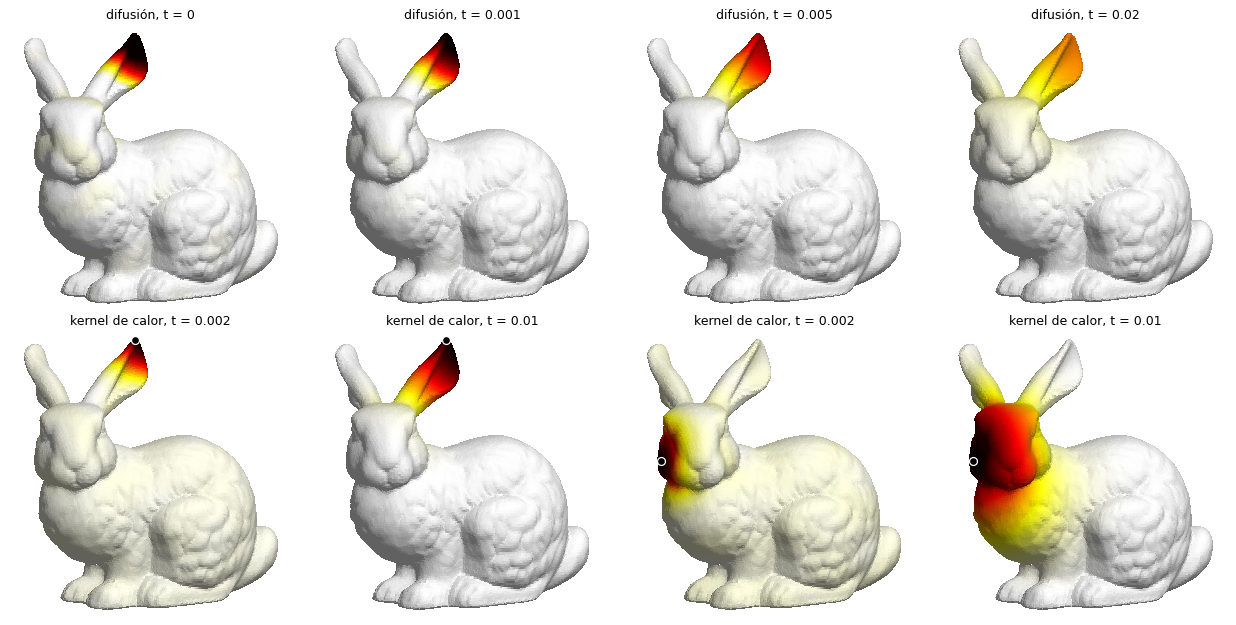

In [43]:
import urllib.request, os
try:
    url = 'https://raw.githubusercontent.com/alecjacobson/common-3d-test-models/master/data/stanford-bunny.obj'
    if not os.path.exists('bunny.obj'):
        urllib.request.urlretrieve(url, 'bunny.obj')
    Vb, Fb = [], []
    for line in open('bunny.obj'):
        if line.startswith('v '): Vb.append([float(x) for x in line.split()[1:4]])
        elif line.startswith('f '): Fb.append([int(x.split('/')[0]) - 1 for x in line.split()[1:4]])
    Vb, Fb = np.array(Vb), np.array(Fb)
    used = np.unique(Fb); remap = -np.ones(len(Vb), int); remap[used] = np.arange(len(used))
    Vb, Fb = Vb[used], remap[Fb]                                   # quitar vértices sin caras
    Vb = (Vb - Vb.mean(0)) / np.sqrt(face_areas(Vb, Fb).sum())     # área 1
    print(f'conejo: {len(Vb)} vértices, {len(Fb)} caras')
    t0 = time.time(); lam_b, Phi_b, L_b, M_b = laplace_spectrum(Vb, Fb, 100); print(f'eigsh: {time.time()-t0:.1f} s')
    ear = int(np.argmax(Vb[:, 1]))                                  # punta de una oreja
    f0b = (np.linalg.norm(Vb - Vb[ear], axis=1) < 0.12).astype(float)
    ts_b = [0, 1e-3, 5e-3, 2e-2]
    Fb_t = heat_diffuse(f0b, lam_b, Phi_b, M_b, ts_b)
    fig, axs = plt.subplots(2, 4, figsize=(14, 7))
    for j, t in enumerate(ts_b):
        render(axs[0, j], Vb, Fb, Fb_t[:, j], cmap='hot_r', vmin=0, vmax=1, view=(10, 20), title=f'difusión, t = {t}')
    snout = int(np.argmin(Vb[:, 0]))                               # hocico
    for j, (x, t) in enumerate([(ear, 2e-3), (ear, 1e-2), (snout, 2e-3), (snout, 1e-2)]):
        render(axs[1, j], Vb, Fb, heat_kernel(lam_b, Phi_b, x, t), cmap='hot_r', view=(10, 20), mark=x, title=f'kernel de calor, t = {t}')
    plt.tight_layout(); plt.show()
except Exception as e:
    print('No se pudo ejecutar el bloque opcional:', e)